# NCAA roster pressure with and without the focal player

This notebook compares observed draft outcomes across three descriptions of the same players’ environments: ordinary leave-one-out (LOO) mean performance, full-group roster pressure, and LOO roster pressure. We keep the familiar populations from mosaic panels 9, 7, and 8 in the **2009–2021** window.

**Start with the top row of the quantile mosaic.** It shows the same 22,795 players three times. Only the horizontal-axis measure and the resulting bin membership change. We can then examine the two high-performance bands one at a time.

This is an empirical exploration. There are no simulated winners, fitted parameters, significance tests, or manuscript edits. The supplied figures are saved with this notebook, and you can rerun the comparison whenever you change the settings.

In [27]:
# EDIT BLANK — session log
# session: 2026-10-23 — new empirical shared versus LOO roster pressure notebook; direct creation authorized.


## 1. Settings you can change

Theta is set from a declared percentile of performance, before we filter to a particular performance band or final-season cohort. Gamma controls how sharply competitive relevance rises around that threshold. The initial values are **exploratory choices**, not fitted estimates or an inferred draft quota.

The all-team and draftee-college pipelines originally standardized performance within their respective populations. We preserve those scales. Their numerical theta values can therefore differ slightly. Panels 7 and 8 use the same source population and theta. Within every row, shared and LOO pressure always use identical theta and gamma.

Both main mosaics are generated: quantile and equal width. Sixteen bins are the default in **all three rows**, so panel 8 does not use its historical four-lower/seven-upper mixed-width bins here. Quantile ties use your original rank-first convention. The separate tie-preserving comparison remains a future task.

### Empirical K, N, and the threshold

On these plots, **K_emp** counts distinct ever-drafted players in the displayed cohort, and **N_emp** counts all distinct players in that cohort. Their ratio is the observed ever-drafted fraction. It does not count fixed annual draft slots. The per-bin N and D rows retain observation counts because those are the denominators and numerators of the plotted bars. In panels 7 and 8, a player can appear in several seasons; their plotted row rate can differ from their unique-player K_emp/N_emp.

Theta is the chosen q-quantile of **full-roster performance**, before final-season or performance-band filtering. Thus q = .93 places theta at the 93rd percentile and leaves a nominal 7% above it. Ties can make the actual fraction differ slightly. Gamma controls the smoothness around theta, so that 7% is not a predicted selection fraction or a fraction given a hard eligibility cutoff.

**We have not imposed q = 1 − K_emp/N_emp.** The all-team final-season cohort has K_emp = 615 and N_emp = 22,795, an observed fraction of approximately 2.70%. A percentile rule explicitly aligned to that fraction would use approximately the 97.30th percentile, not the current 93rd. That would be a new modeling choice requiring an agreed selection population and time horizon. Panels 7 and 8 report rates conditional on their high-performance bands and college restriction; those rates should not be substituted for the overall selection fraction.

Every figure reports the settings and empirical counts. The file `empirical_selection_context.csv` saves these values for the run.


In [ ]:
SETTINGS = {
    "theta_quantile": 0.97,  # .93 = 93rd percentile of full-roster performance. Higher values raise the competitive standard.
    "gamma": 6.0,           # Positive sharpness: .5 gives a broad transition; 2 moderate; 8 much sharper.
    "n_bins": 16,           # Quantile: approximately equal observation counts. EW: equally spaced score boundaries.
    "thin_n": 30,           # Open circles flag bins with fewer than this many observations; those bins remain visible.
    "show_squid_jackal": True,  # With 16 bins: green = quantile bins 6–8; orange = 14–16. EW shows their score ranges.
    "sensitivity_quantiles": [0.80, 0.90, 0.93],  # Show EVERY listed threshold, not just a visually favorable result.
    "sensitivity_gammas": [0.5, 2.0, 8.0],        # Show EVERY listed gamma crossed with every threshold above.
}
REBUILD_FIGURES = True       # True runs the comparison and saves a new dated output folder. False displays a matching saved run.
REFRESH_SOURCE_DATA = False # True reconstructs the local input panels. False uses them only if source/code fingerprints still match.
RUN_SENSITIVITY = True       # Also generate the three 3-by-3 theta/gamma comparison sheets; no significance tests.


## 2. Reproduce the source populations and run the comparison

The reconstruction must reproduce the saved original bin counts and draft-positive counts before making new plots. The two shared/LOO pressure measures are calculated on the full eligible team-season rosters **before** selecting final-season observations or high-performance bands. A singleton’s LOO value is undefined, not zero.

The source rules require at least 20 player minutes and more than 10 recorded team-season games. “Ever drafted” remains the outcome in every plot. In panels 7 and 8, an ever-drafted player may contribute several positive player-season rows; those are not several different draft selections.

In [29]:
from pathlib import Path
import sys, json, importlib
import pandas as pd
from IPython.display import display, Image, Markdown

relative = Path("3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison")
roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
HERE = next((p for root in roots for p in [root, root / relative,
            root / "manuscript_figures/section_4_5/roster_pressure_comparison"]
            if (p / "roster_pressure_analysis.py").is_file()), None)
if HERE is None:
    raise FileNotFoundError("Open this notebook in the project workspace with its companion analysis file.")
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import roster_pressure_analysis as analysis
analysis = importlib.reload(analysis)

if REBUILD_FIGURES:
    RUN_FOLDER, summary, provenance = analysis.run(
        SETTINGS, refresh_sources=REFRESH_SOURCE_DATA, sensitivity=RUN_SENSITIVITY)
else:
    saved = json.loads((HERE / "latest_run.json").read_text())
    if saved["settings"] != SETTINGS:
        raise RuntimeError("The visible settings differ from the saved figures. Set REBUILD_FIGURES = True and rerun.")
    RUN_FOLDER = Path(saved["run_directory"])
    summary = pd.read_csv(RUN_FOLDER / "paired_comparison_summary.csv")
    provenance = json.loads((RUN_FOLDER / "methods_and_provenance.json").read_text())
    if provenance["code_sha256"] != analysis.sha256(analysis.__file__):
        raise RuntimeError("Analysis code changed after this saved run. Rebuild the figures.")
settings_at_run = json.dumps(SETTINGS, sort_keys=True)

def require_current_run():
    if json.dumps(SETTINGS, sort_keys=True) != settings_at_run:
        raise RuntimeError("Settings changed. Rerun section 2 before displaying the figures.")

print("Output folder:", RUN_FOLDER)
print("Original source validation:", provenance["source"]["verification"]["check"])
print("Theta values:", provenance["thresholds"])
print("Undefined singleton LOO observations:", provenance["undefined_loo_rows"])
display(summary[["panel", "observations", "distinct_players", "positive_rows",
                 "distinct_drafted_players", "colleges", "college_seasons"]])


Loaded unchanged, fingerprint-checked local source snapshots.
Verified original bin counts and cohorts for panels 9, 7, and 8.
 panel  observations  distinct_players  positive_rows  distinct_drafted_players  colleges  college_seasons  median_shared  median_loo  median_paired_change  loo_lower_percent  rank_correlation  changed_quantile_bin_percent
     9         22795             22795            615                       615       362             4508       0.082392    0.081833              0.004940          20.021935          0.922923                     68.488704
     7           534               441            175                       142       136              473       0.142513    0.067255             -0.076737         100.000000          0.975543                     55.617978
     8          1546              1127            418                       293       144             1139       0.134949    0.066566             -0.069735         100.000000          0.956197            

,panel,observations,distinct_players,positive_rows,distinct_drafted_players,colleges,college_seasons
0,9,22795,22795,615,615,362,4508
1,7,534,441,175,142,136,473
2,8,1546,1127,418,293,144,1139


## 3. What changes mathematically

First, transform each player’s own performance into competitive relevance:

$$v_h=\frac{1}{1+e^{-\gamma(A_h-\theta)}}.$$

For a team with n members, **full-group roster pressure** averages every member’s relevance. **LOO roster pressure** removes the focal player and averages the other n−1 members. It is the average of their individually transformed values, not the sigmoid of their average performance.

$$C_{\mathrm{shared},j}=\frac{1}{n_j}\sum_{h:g(h)=j}v_h,\qquad
C_{\mathrm{LOO\text{-}RP},i}=\frac{\sum_{h:g(h)=g(i)}v_h-v_i}{n_{g(i)}-1}.$$

These are working labels for this experiment, not a decision to rename the manuscript’s notation. In particular, LOO roster pressure is different from C_LOO,i, the manuscript’s ordinary average of other members’ performance.

The difference has a simple interpretation:

$$C_{\mathrm{LOO\text{-}RP},i}-C_{\mathrm{shared},g(i)}
=\frac{C_{\mathrm{shared},g(i)}-v_i}{n_{g(i)}-1}.$$

If the focal player has above-average competitive relevance for that team, excluding them lowers the average. If their relevance is below the team average, excluding them raises it. The size of that change depends on both the player and roster size. It need not be the same horizontal shift for everyone.

## 4. Quantile mosaic

**Rows:** panel 9 population, then panel 7 band, then panel 8 band. **Columns:** ordinary LOO performance, full-group roster pressure, LOO roster pressure.

Each curve has approximately equal numbers of observations per bin. Equal values can be split using source row order, as in your previous quantile plots. Shared and LOO pressure have matching display scales, but their quantile boundaries and memberships are calculated separately. Do not treat a shared-pressure bin and the same-numbered LOO bin as the same people.

Counts below every plot are **N** observations, **D** draft-positive observations, and **G** distinct college-seasons. The complete output also distinguishes unique players, unique drafted players, colleges, and college-seasons with drafted players. Distinct counts should not be added across bins because the same person or group can occur in more than one.

No horizontal-axis values are winsorized in these new plots. This differs from the historical LOO curves, whose extremes were clipped at the 1st and 99th percentiles. All source populations are preserved, but the left-hand reference is deliberately replotted under the new common binning policy.

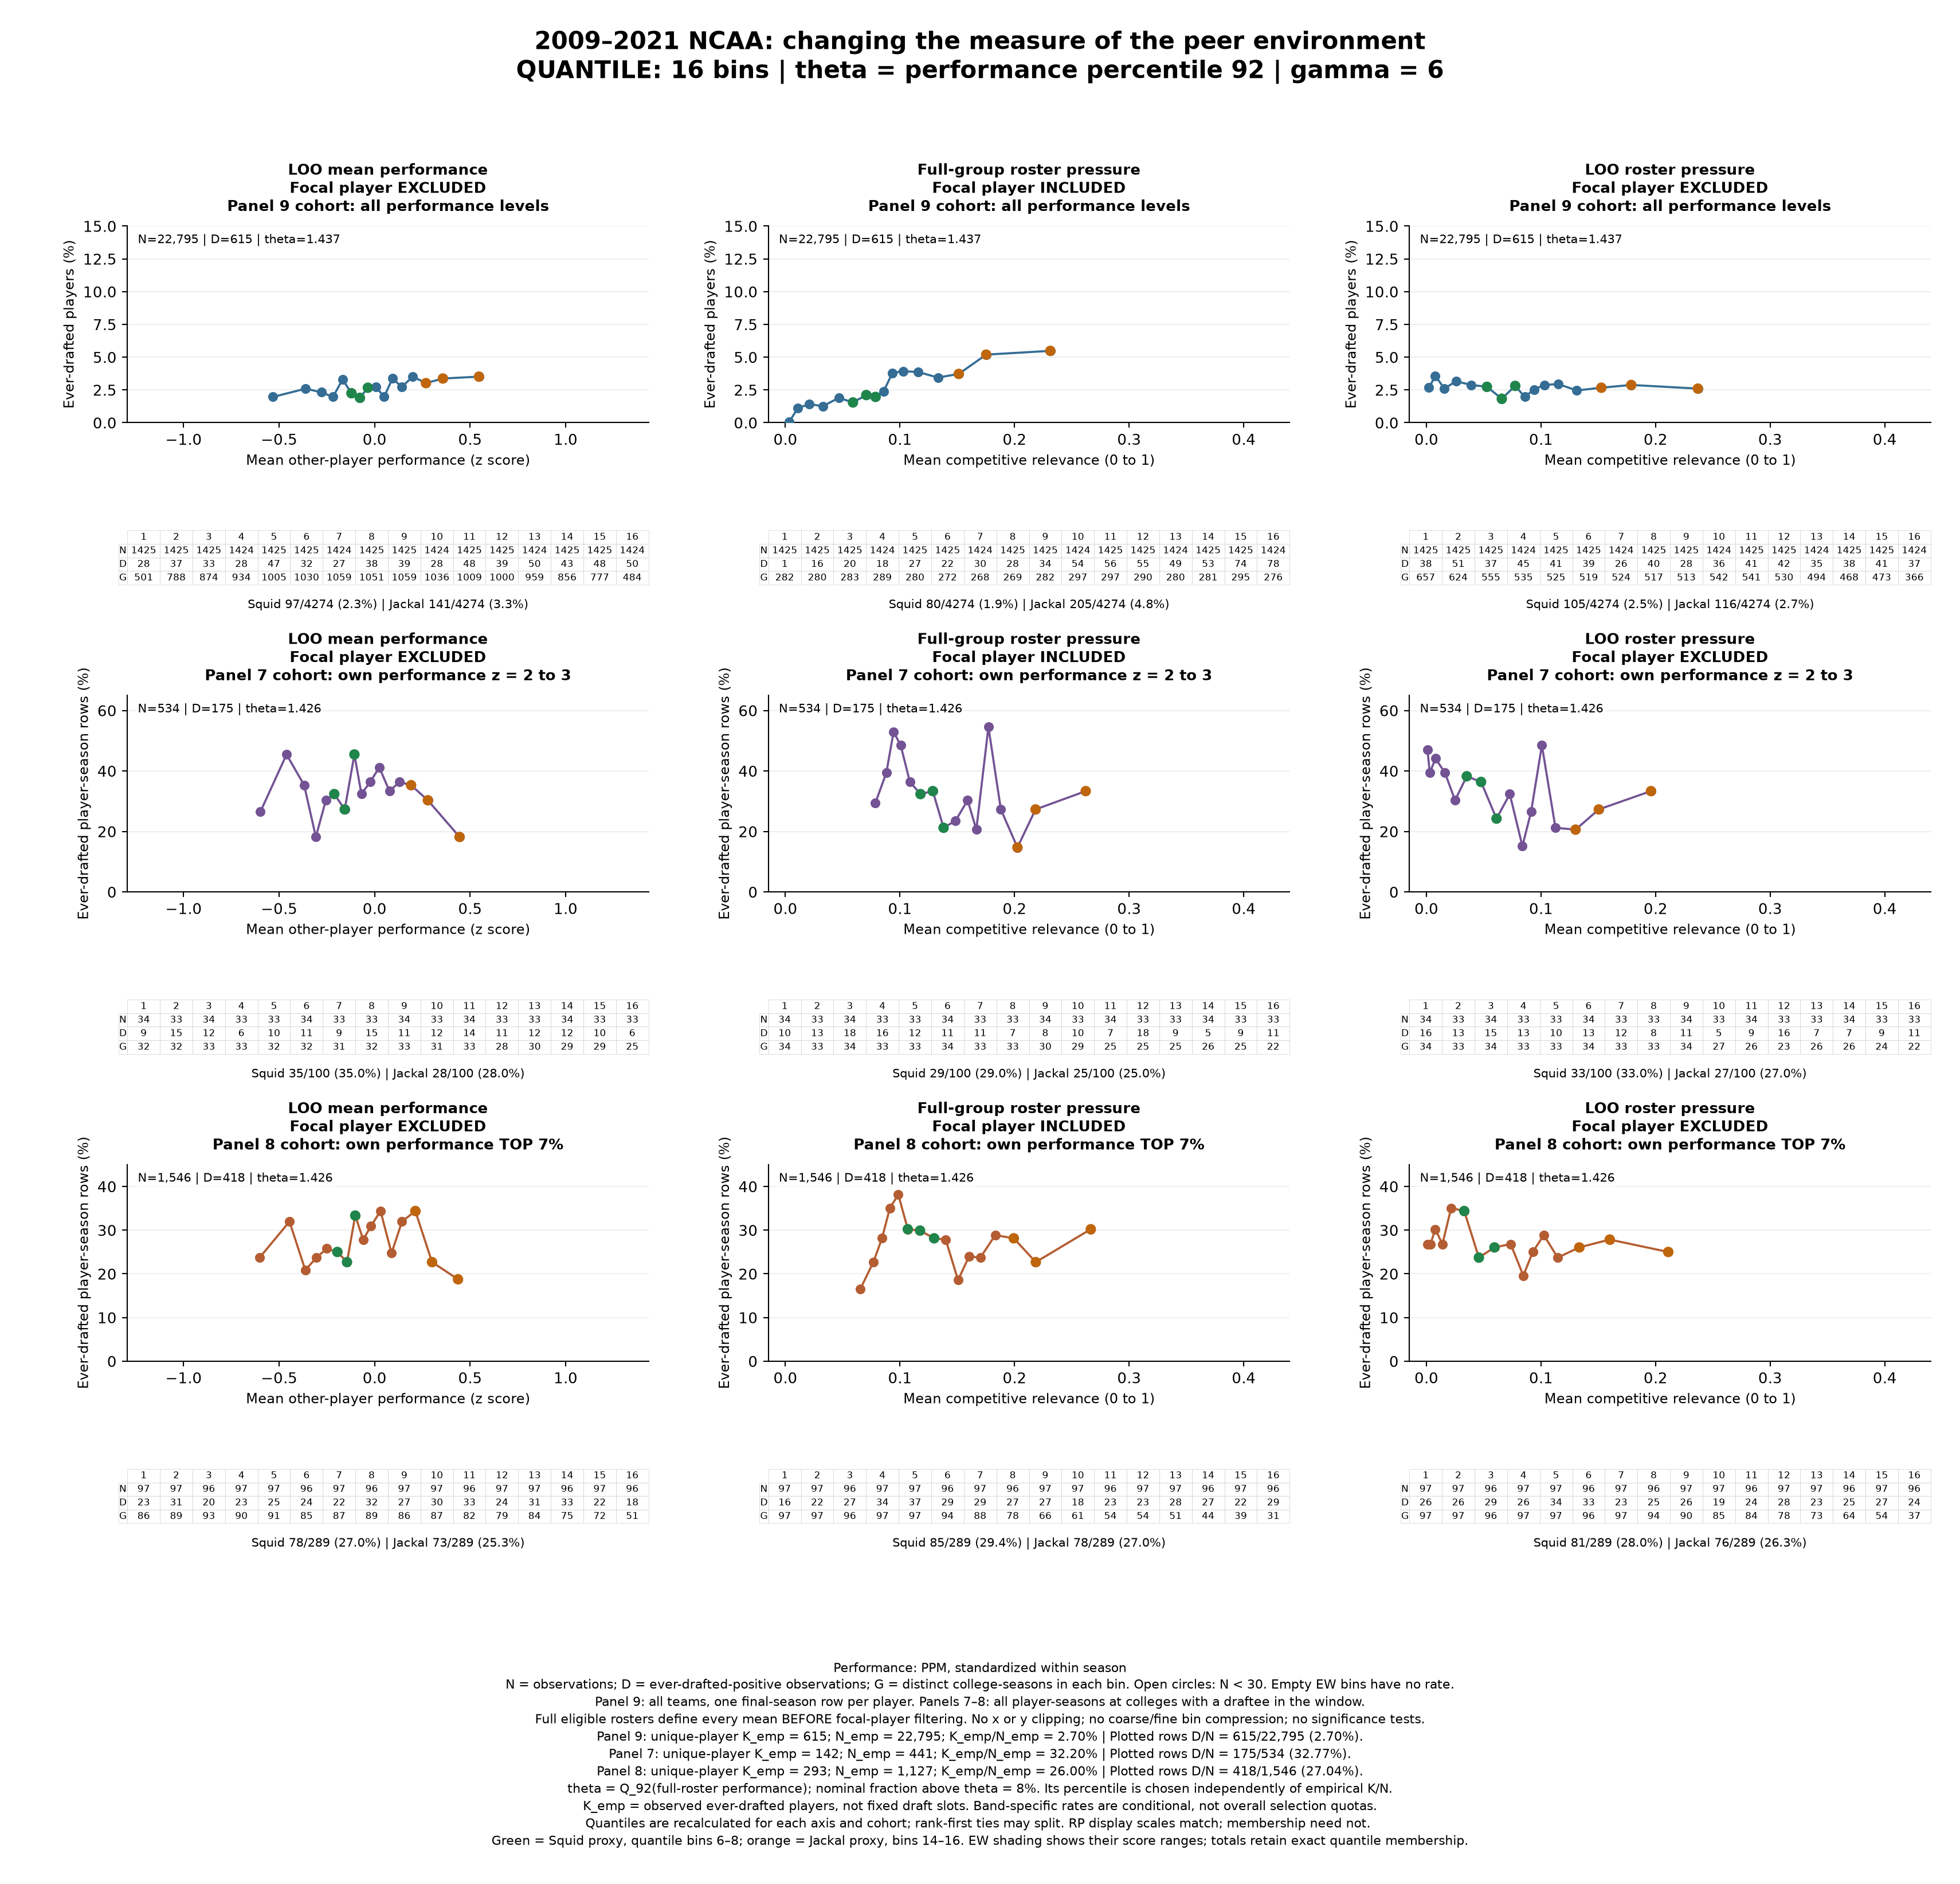

In [30]:
require_current_run()
display(Image(filename=str(RUN_FOLDER / "roster_pressure_mosaic_quantile.png"), width=1500))


## 5. Equal-width mosaic

Here the shared and LOO roster-pressure columns use **exactly the same physical bin edges**, across all three rows. The ordinary-performance column has its own edges because z scores and competitive relevance have different units. All values are included; empty bins have no estimated rate and open circles flag small counts.

This view lets us compare the same ranges of roster pressure. It can also expose how little data support an apparent extreme-bin spike or downturn. A 100% rate based on one observation is shown, not hidden.

The green and orange regions retain the quantile-defined Squid and Jackal proxies. On an EW plot, shading shows their minimum-to-maximum scores; the printed totals use exact quantile membership. A tied boundary value or an EW bin can contain observations outside that exact membership. Neither label is a permanent player category.

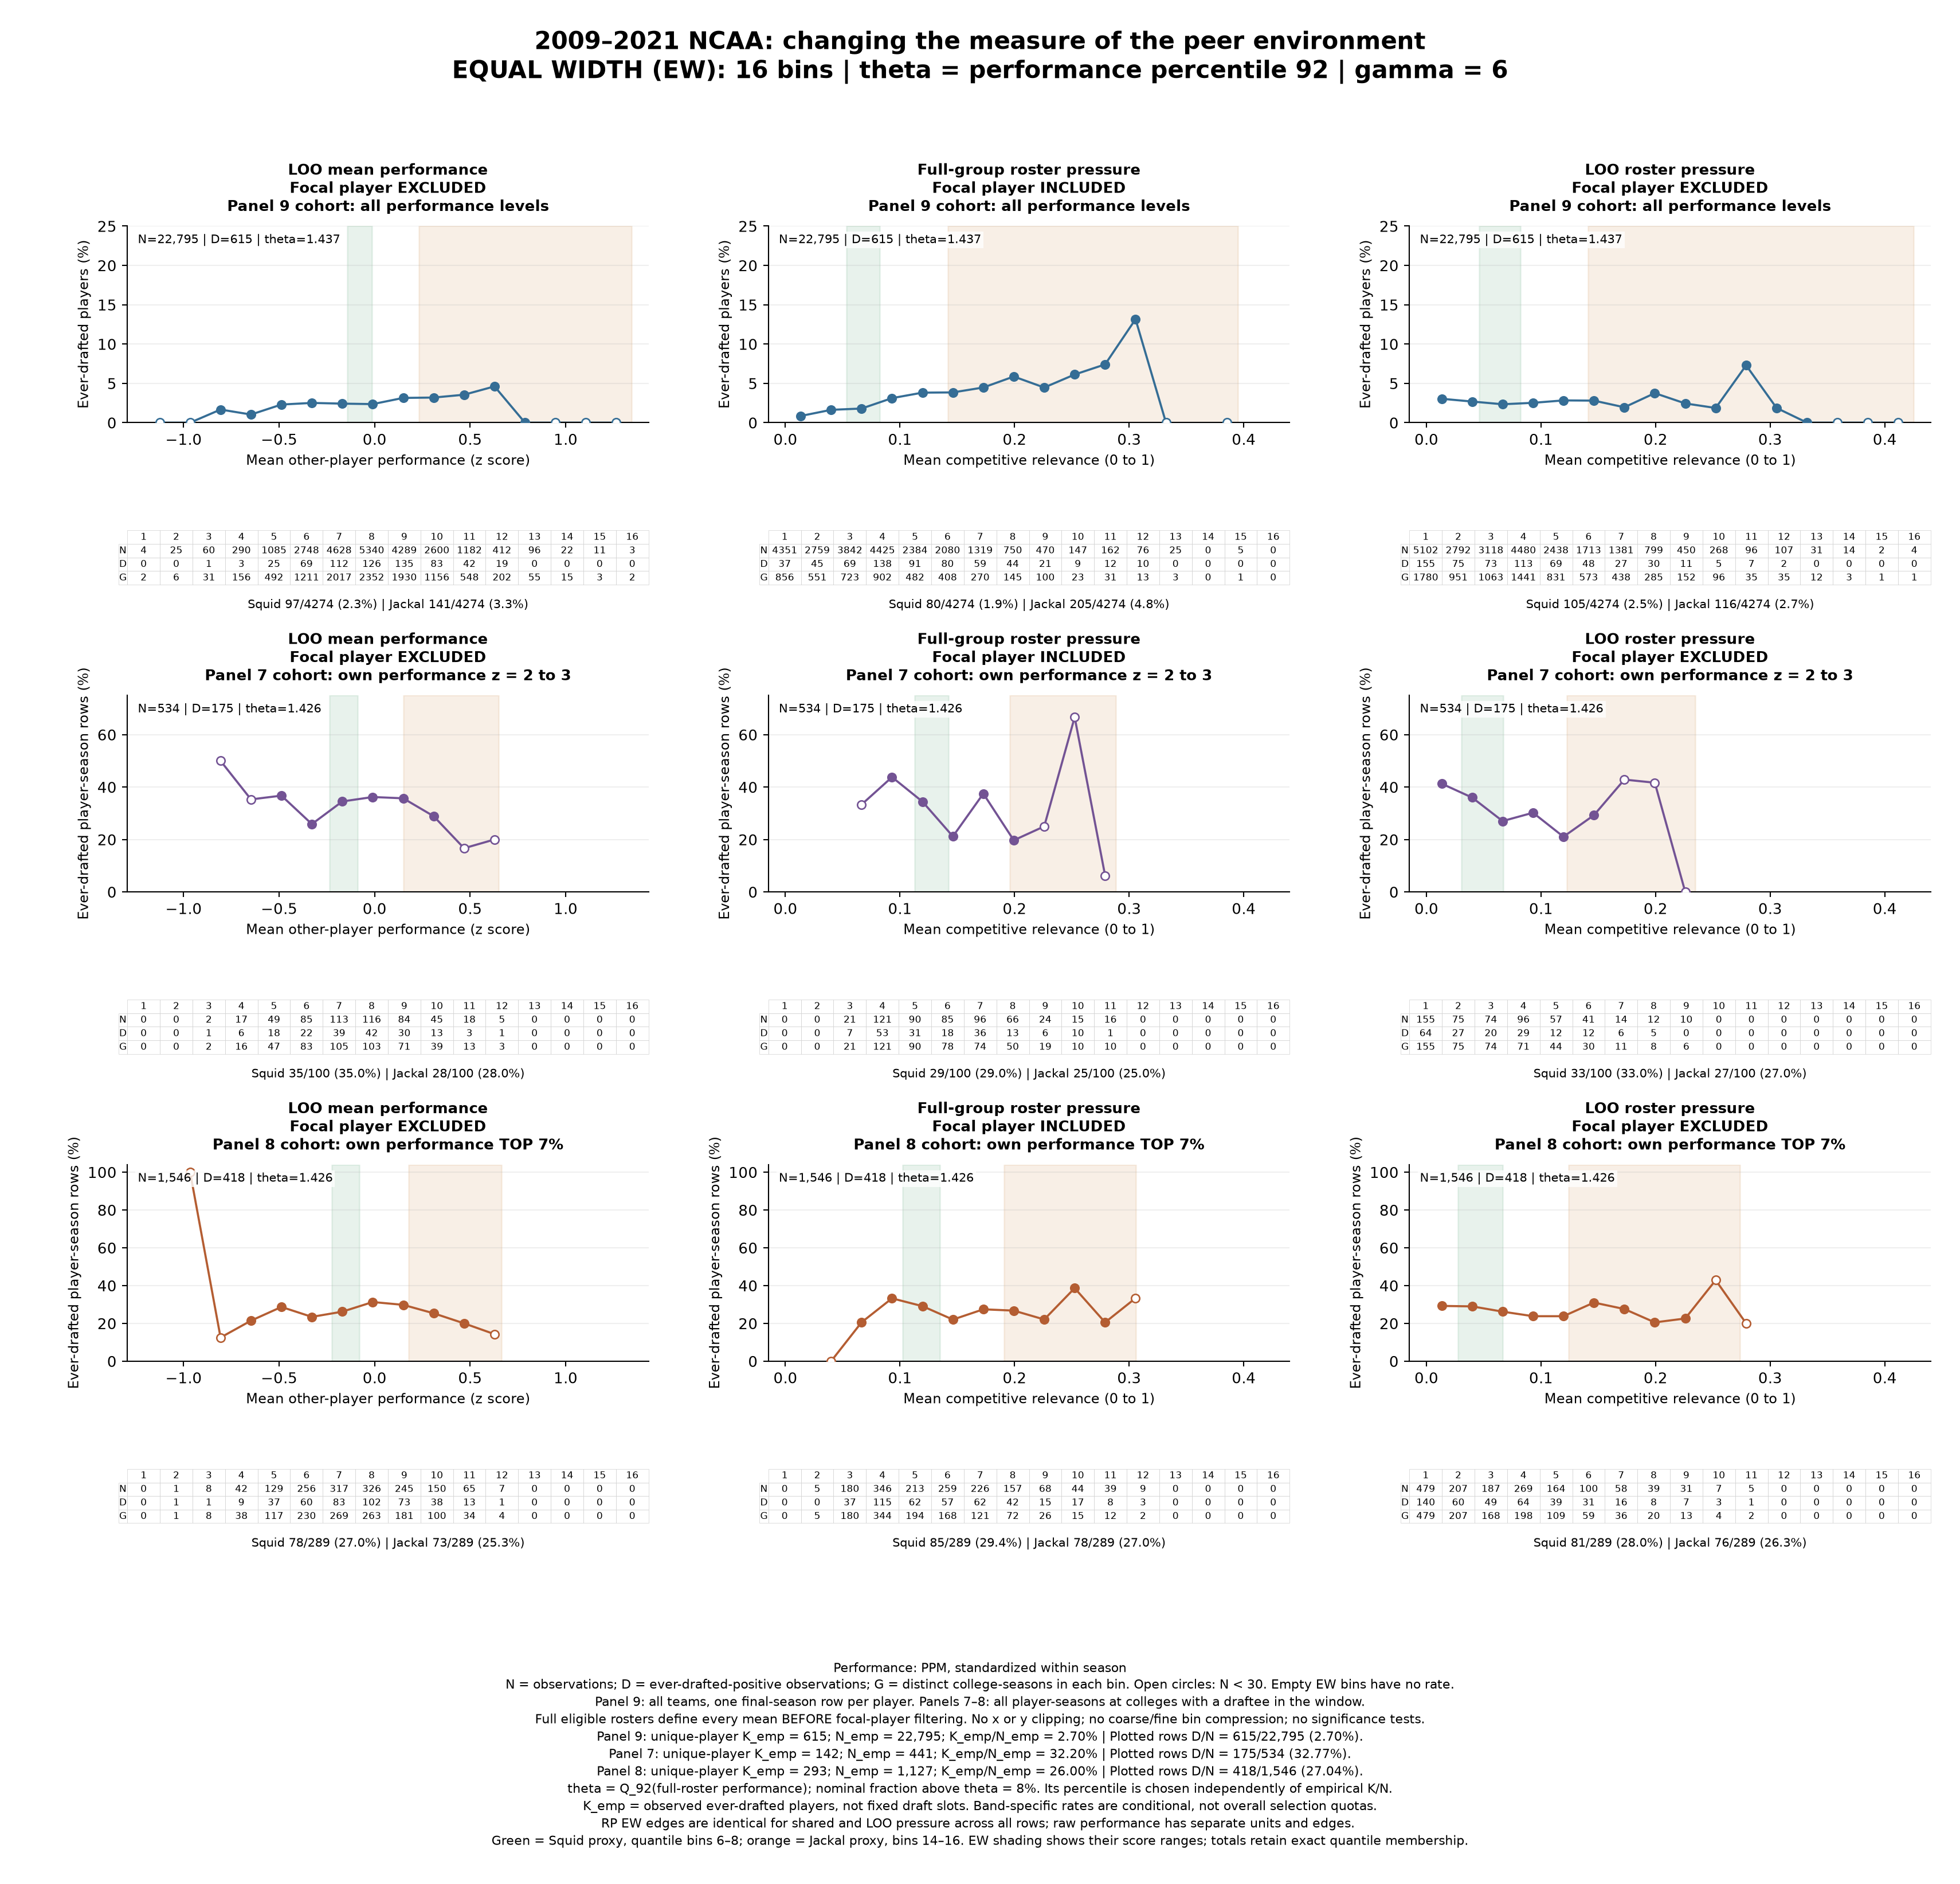

In [31]:
require_current_run()
display(Image(filename=str(RUN_FOLDER / "roster_pressure_mosaic_EW.png"), width=1500))


## 5A. Old-school HERO bars: shared versus LOO roster pressure

These charts use **the exact same observations, bins, and draft counts as the mosaics**. Only the display changes: one bar per numbered bin, with shared roster pressure on the left and LOO roster pressure on the right. Each pair uses the same vertical scale.

**N** is the number of observations; **D** is the number labeled ever drafted; **G** is the number of distinct college-seasons. Each bar is **100 × D/N**. Panel 9 has one final-season observation per player. Panels 7 and 8 contain player-season observations, so their D totals are not counts of distinct drafted players. Distinct-player totals also appear beneath each pair.

Theta and gamma are printed on every figure. Theta is an exploratory performance percentile, not an estimated threshold or an observed draft-capacity calibration. The full eligible rosters determine pressure before any performance-band or final-season filtering.

Quantiles are recalculated separately for shared and LOO pressure. Equal-width charts use matching physical edges. Hatched bars flag small bins; empty bins have no bar or estimated rate. There is no clipping, bin compression, or new significance testing. The bars use a single color, without the mosaics' Squid/Jackal highlighting.

### Quantile HERO comparisons

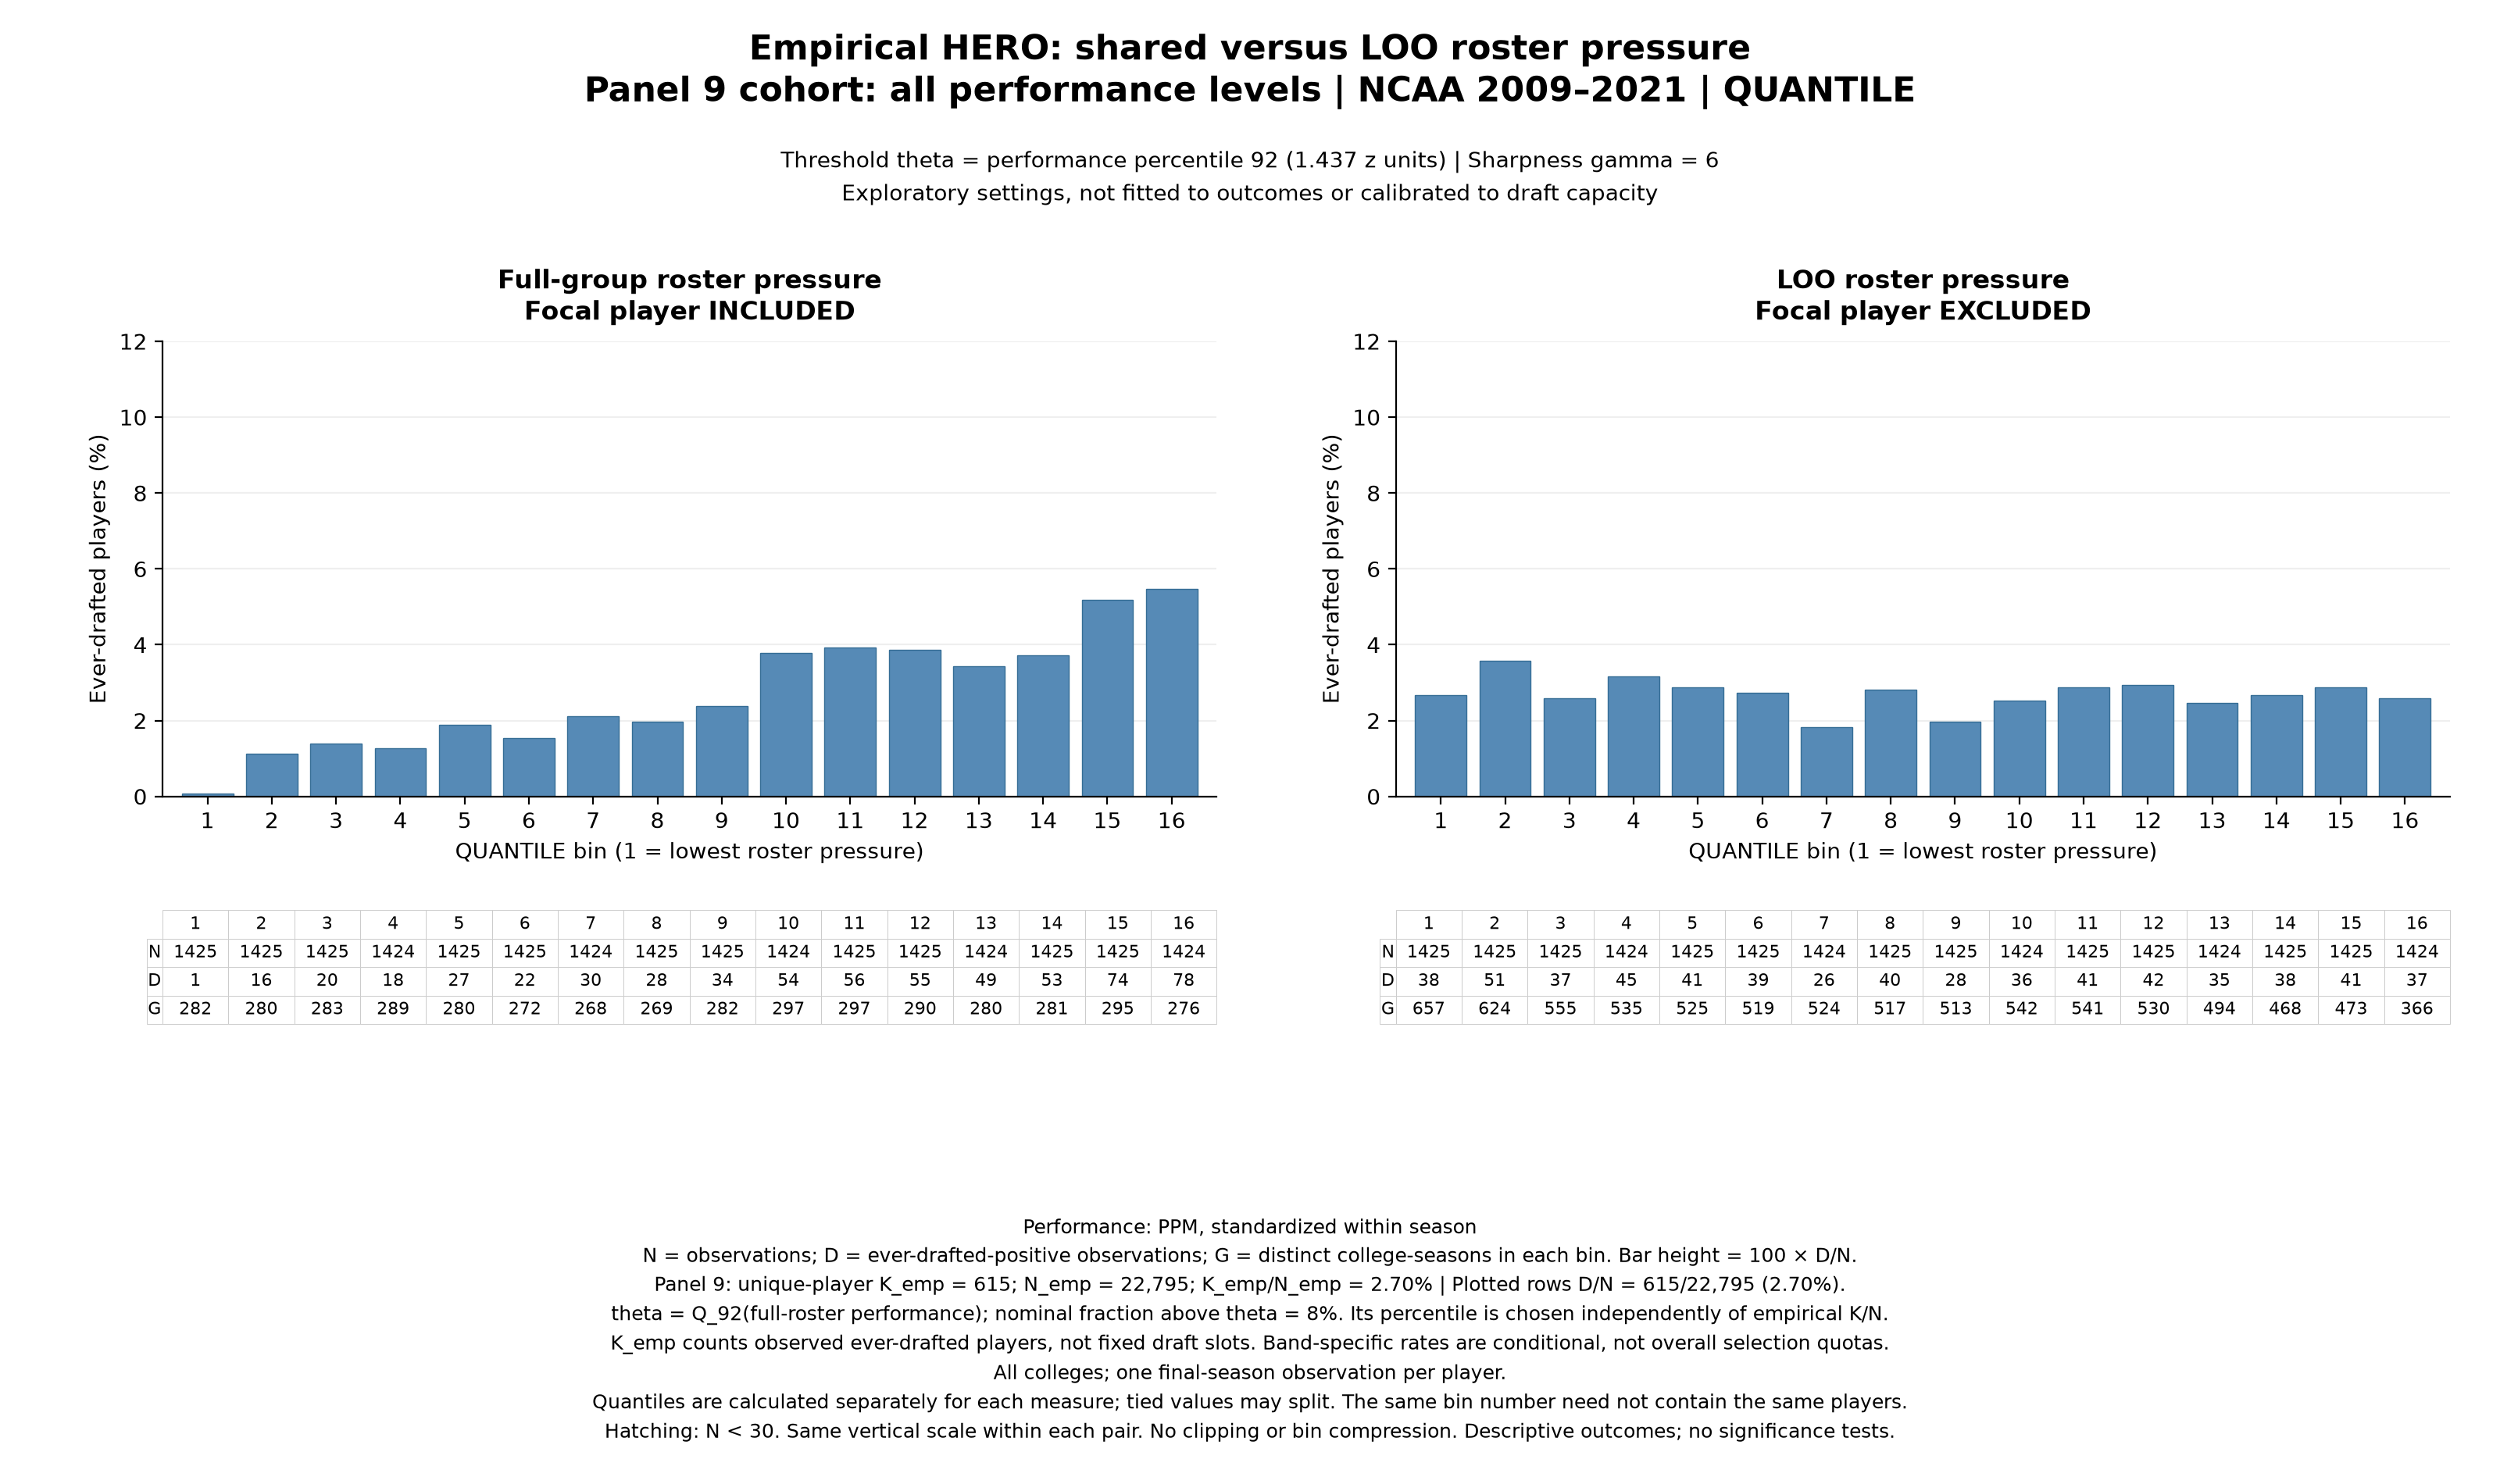

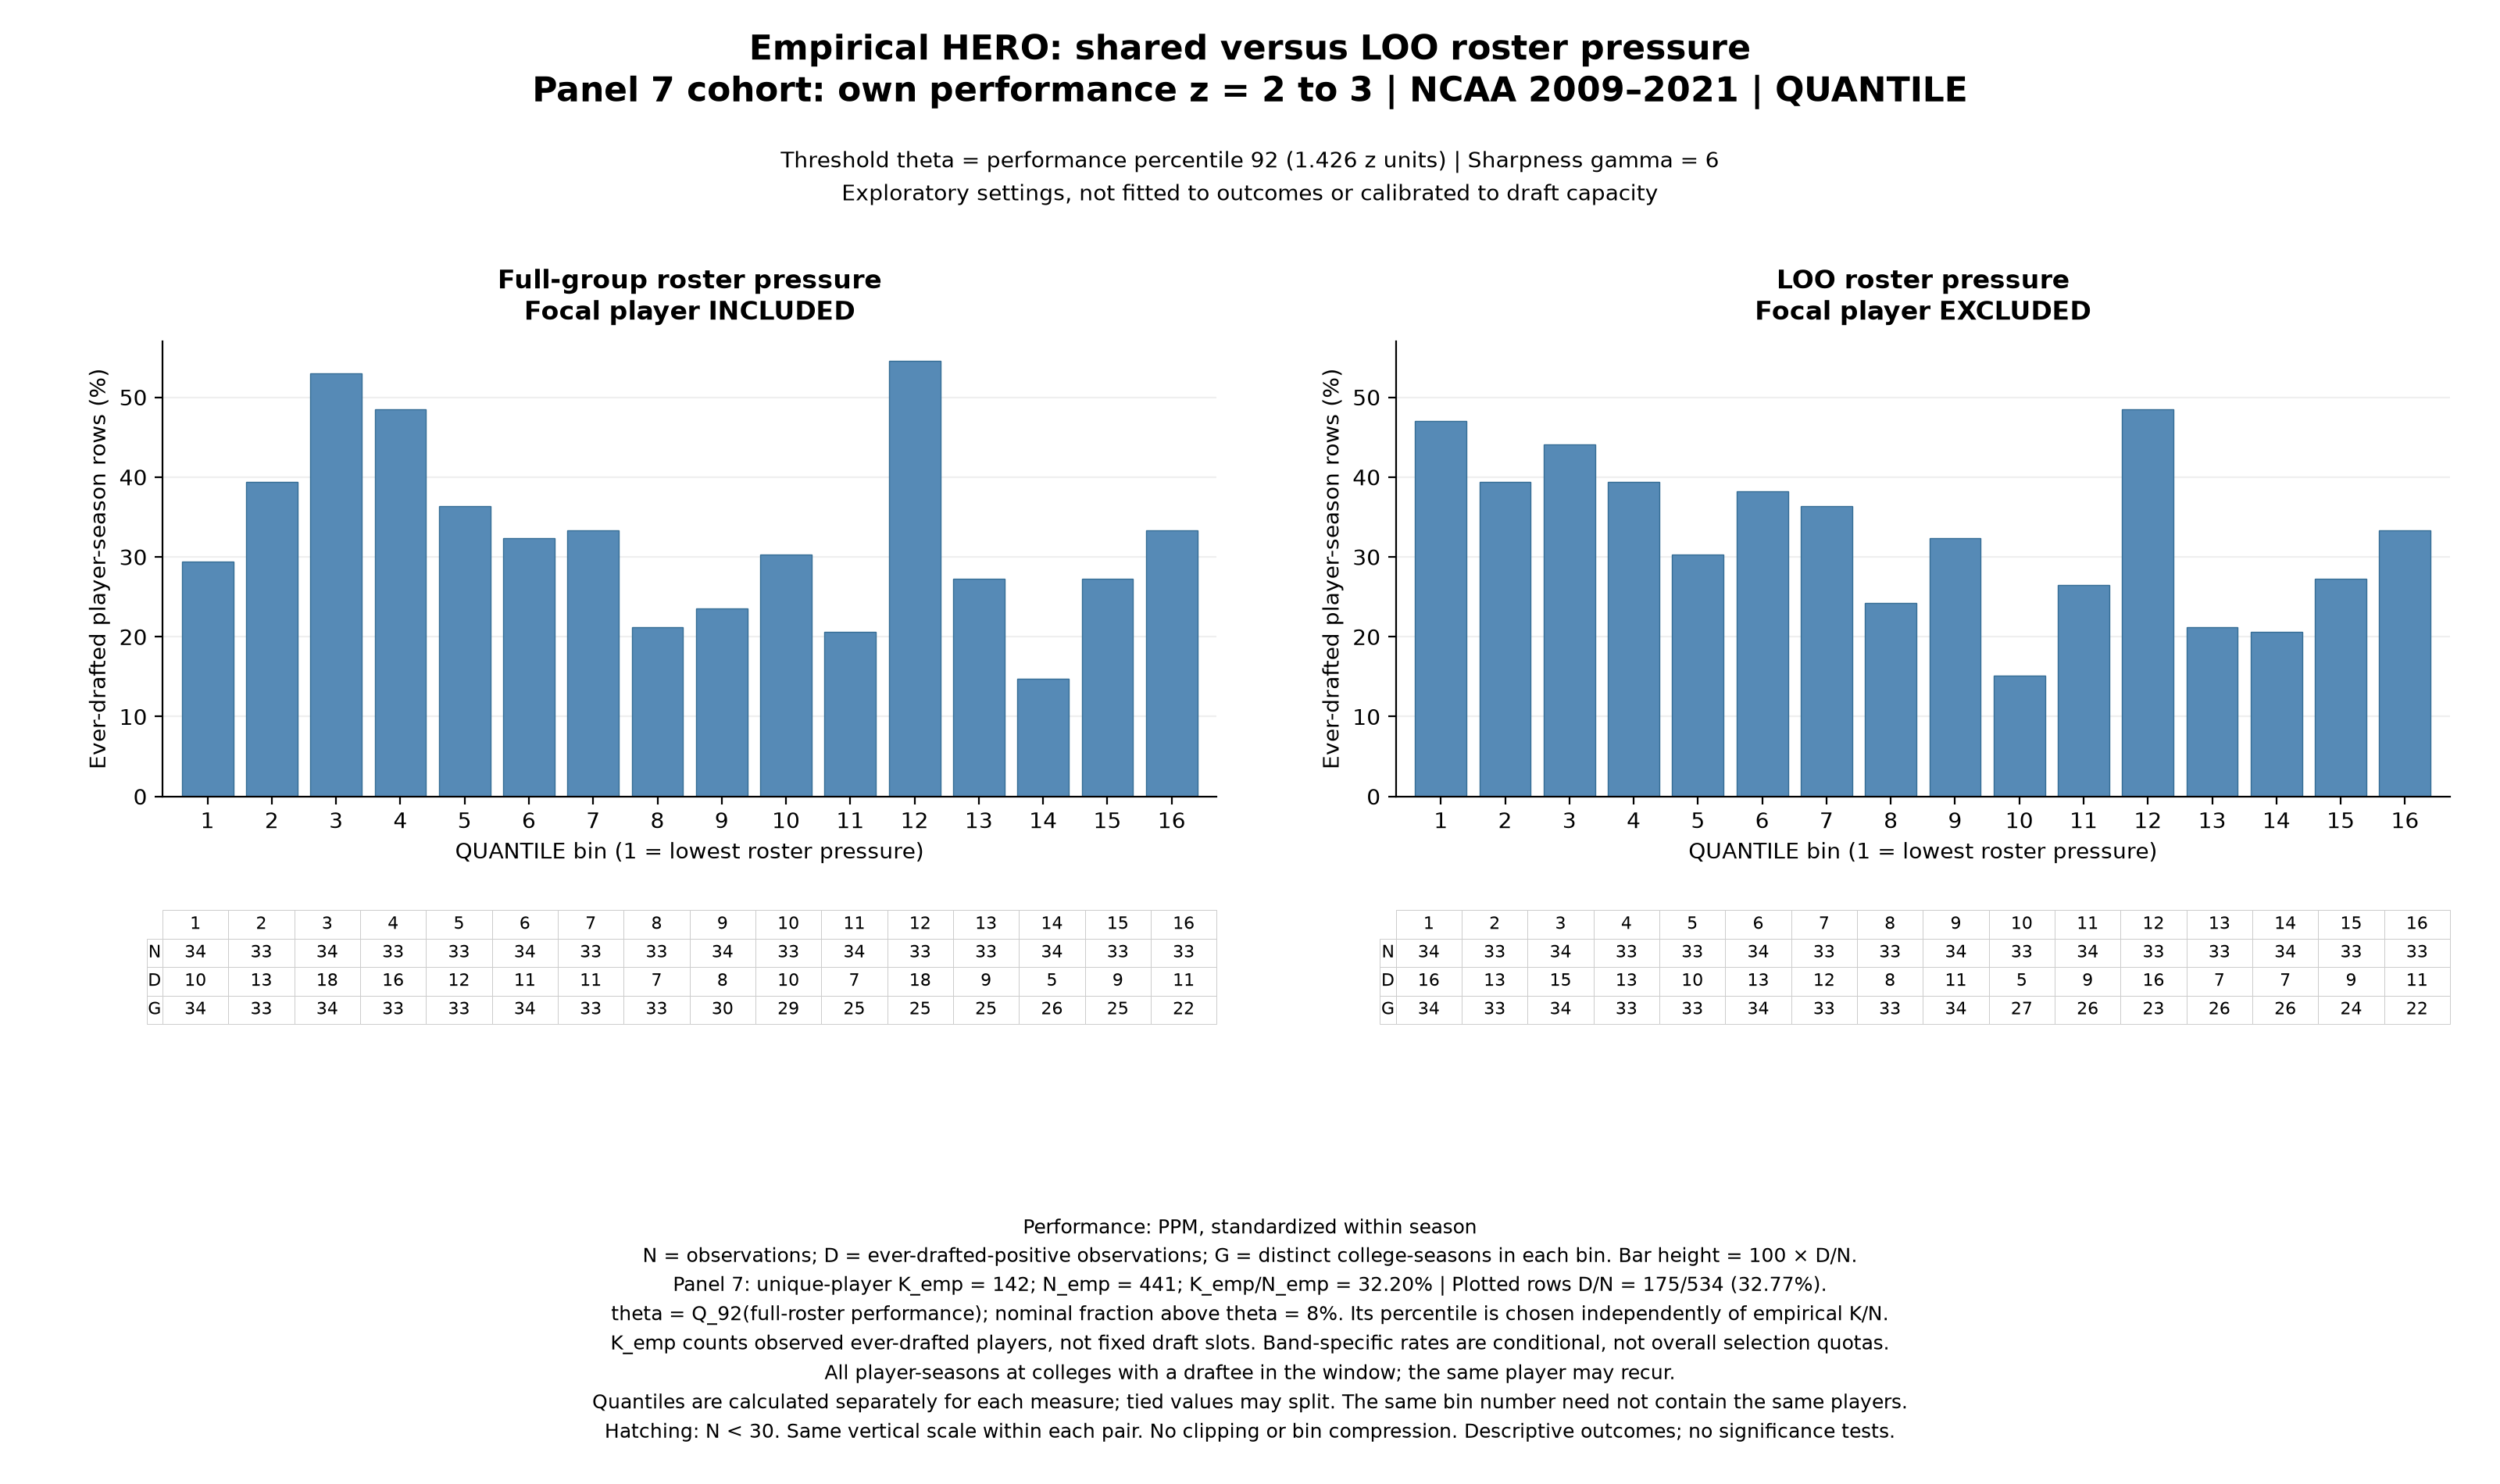

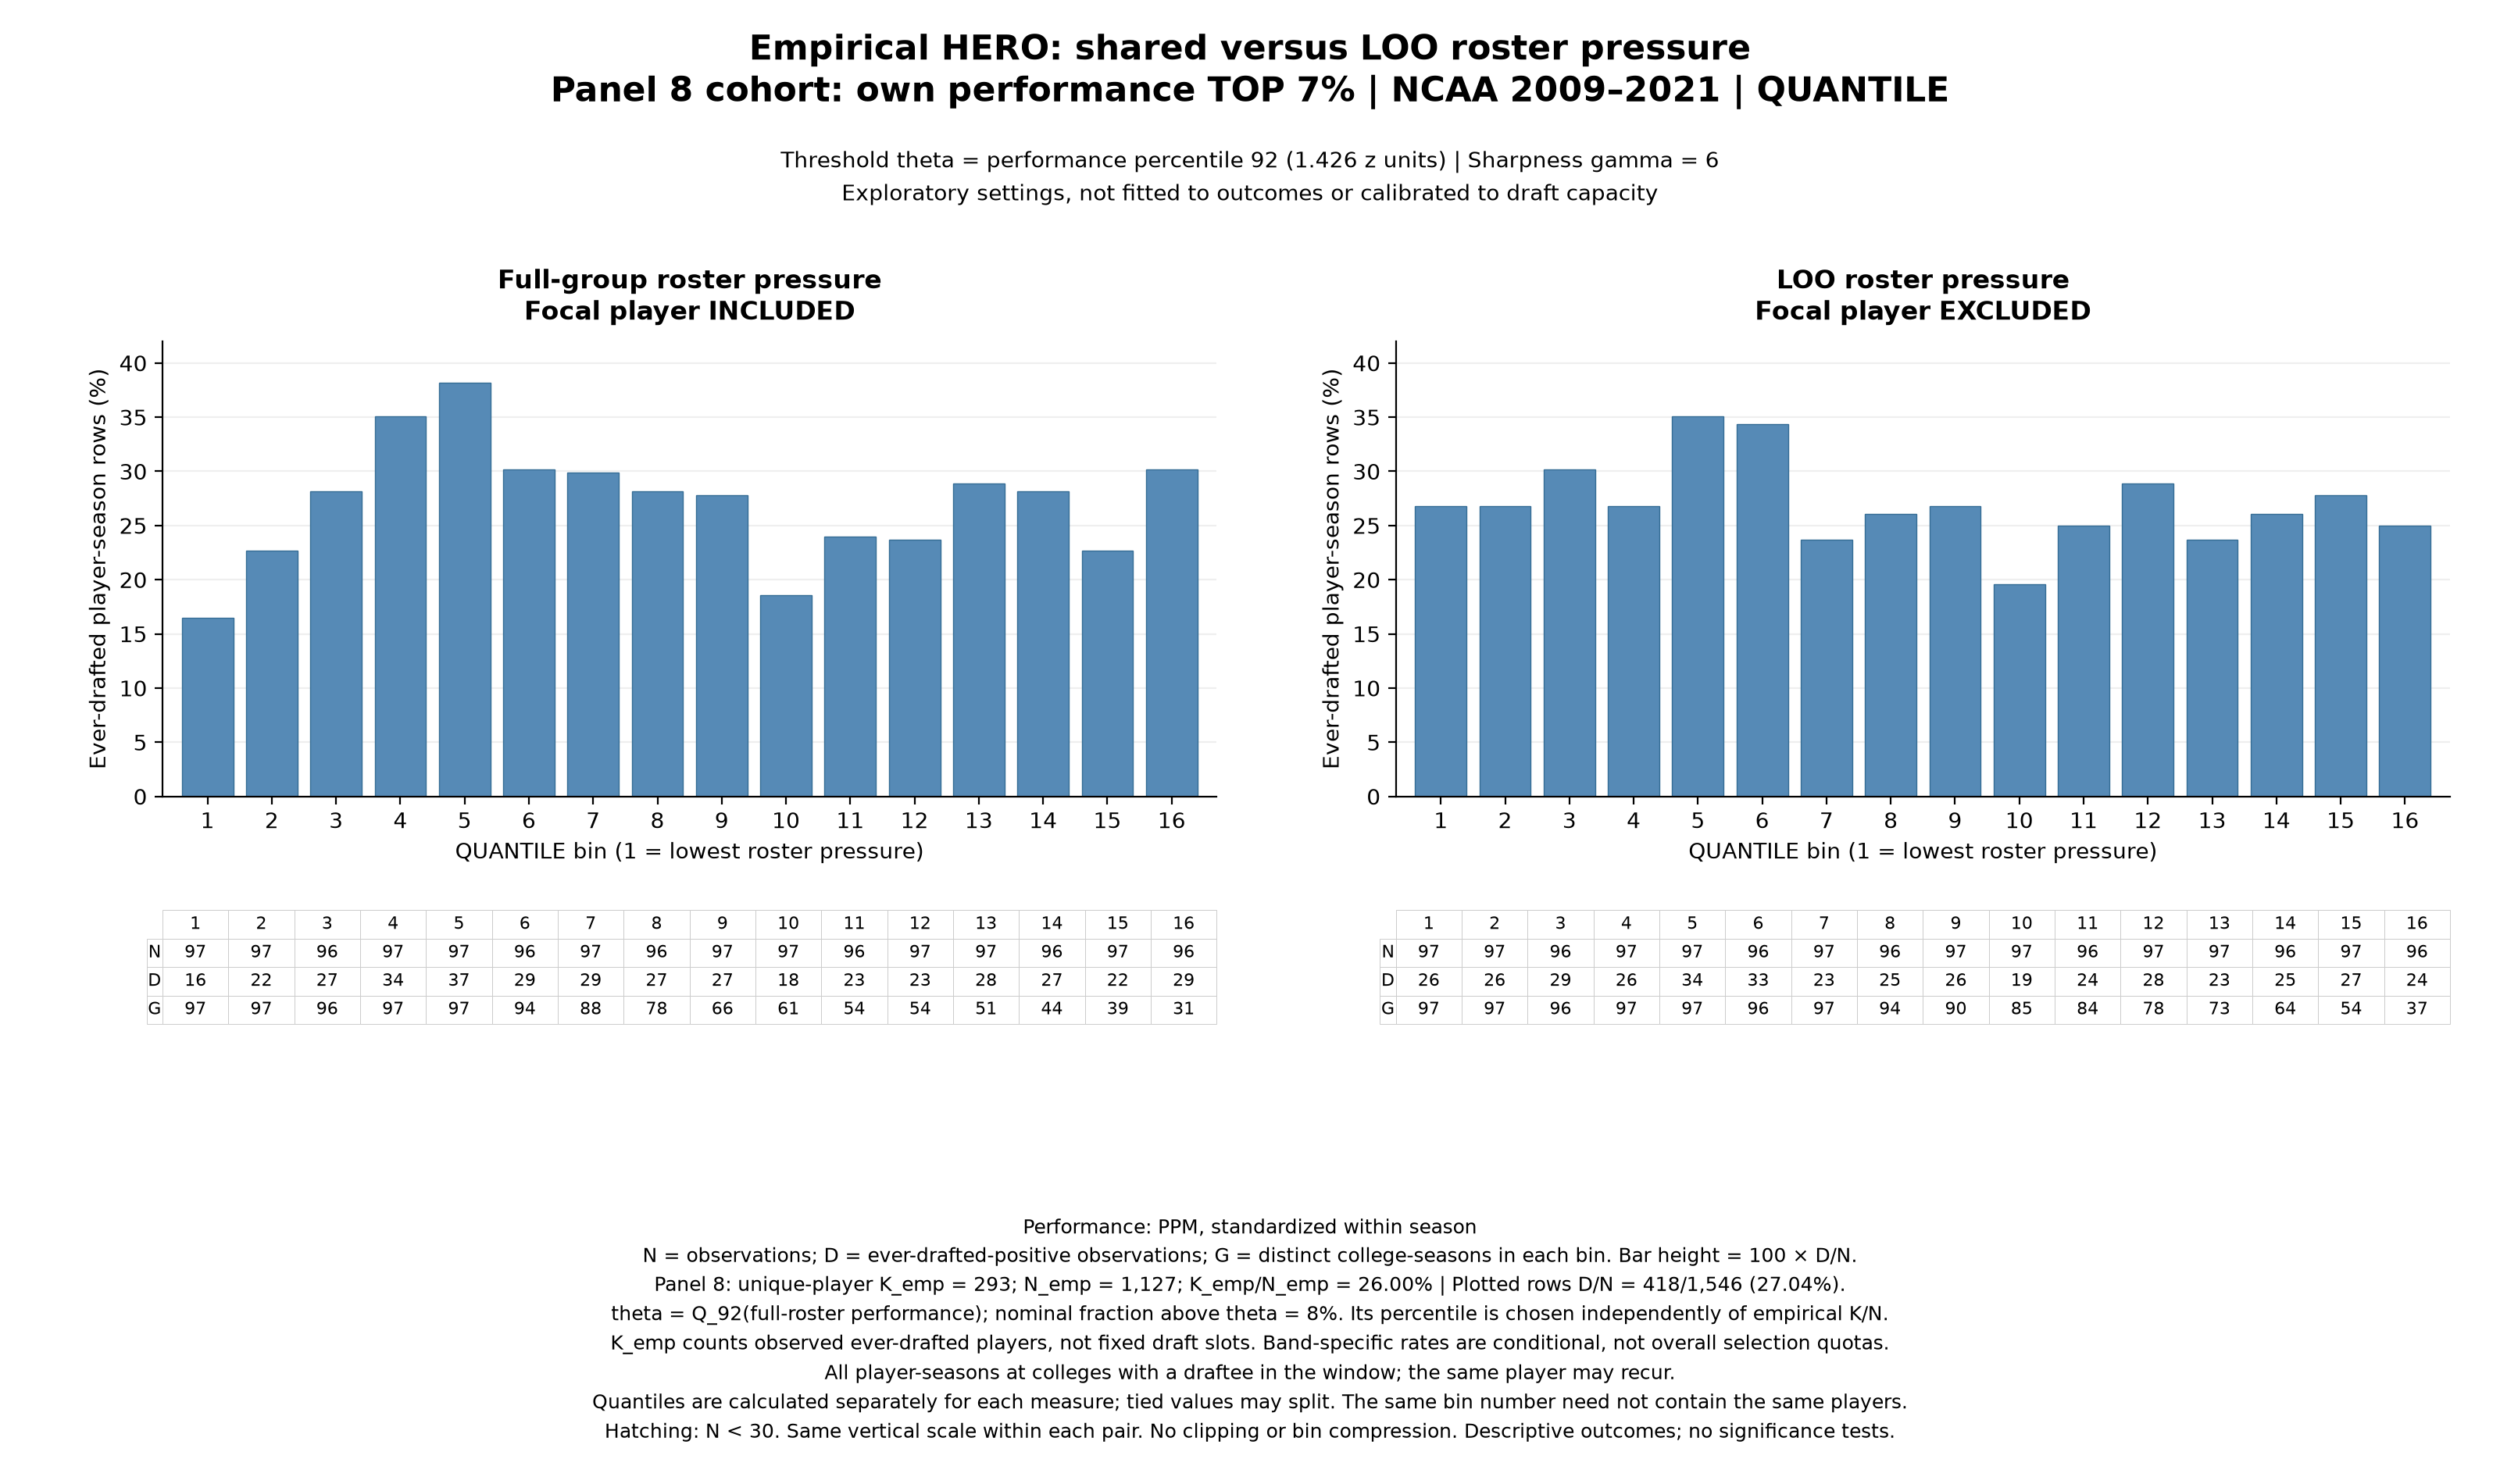

Printable HERO comparisons: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison/runs/20261023_113742_690479/HERO_roster_pressure_printable.pdf


In [32]:
require_current_run()
for panel in [9, 7, 8]:
    display(Image(filename=str(RUN_FOLDER / f"HERO_panel{panel}_quantile_shared_vs_LOO.png"), width=1500))
print("Printable HERO comparisons:", RUN_FOLDER / "HERO_roster_pressure_printable.pdf")

### Equal-width HERO comparisons

Here the same bin number denotes the same physical roster-pressure interval in both charts. Counts can differ substantially across bins; consult the N and D rows before interpreting a tall or short bar.

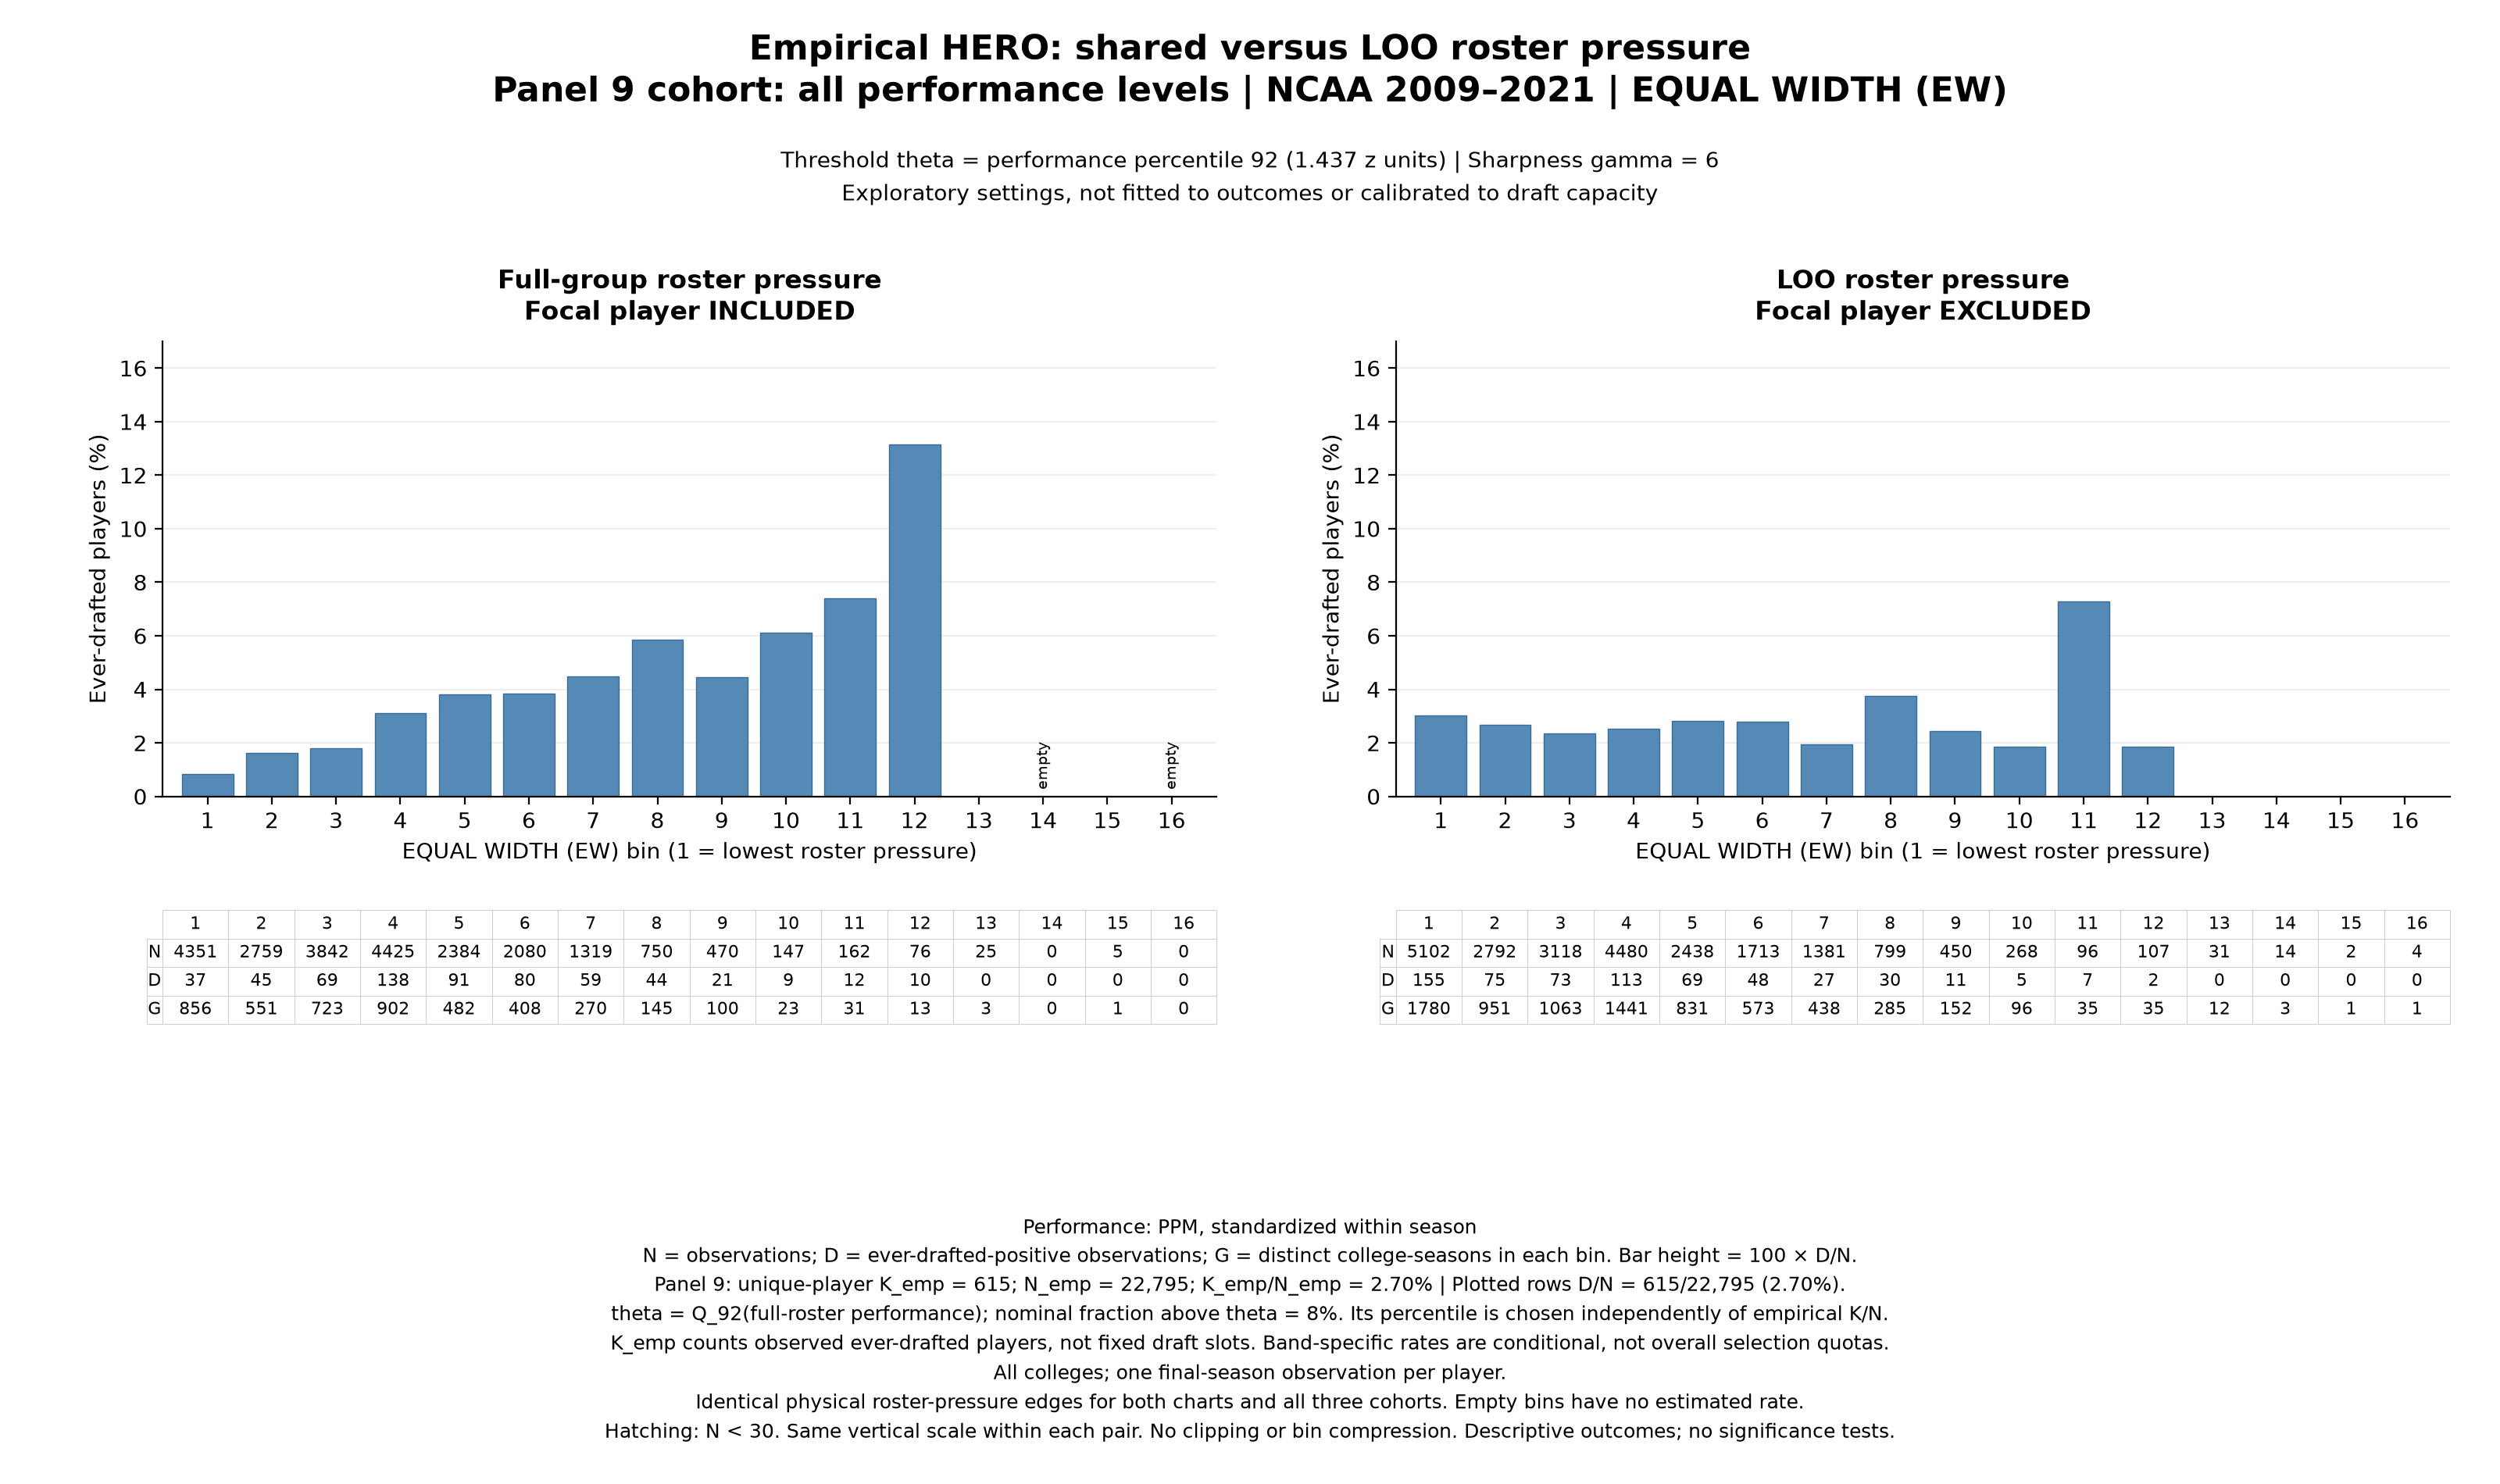

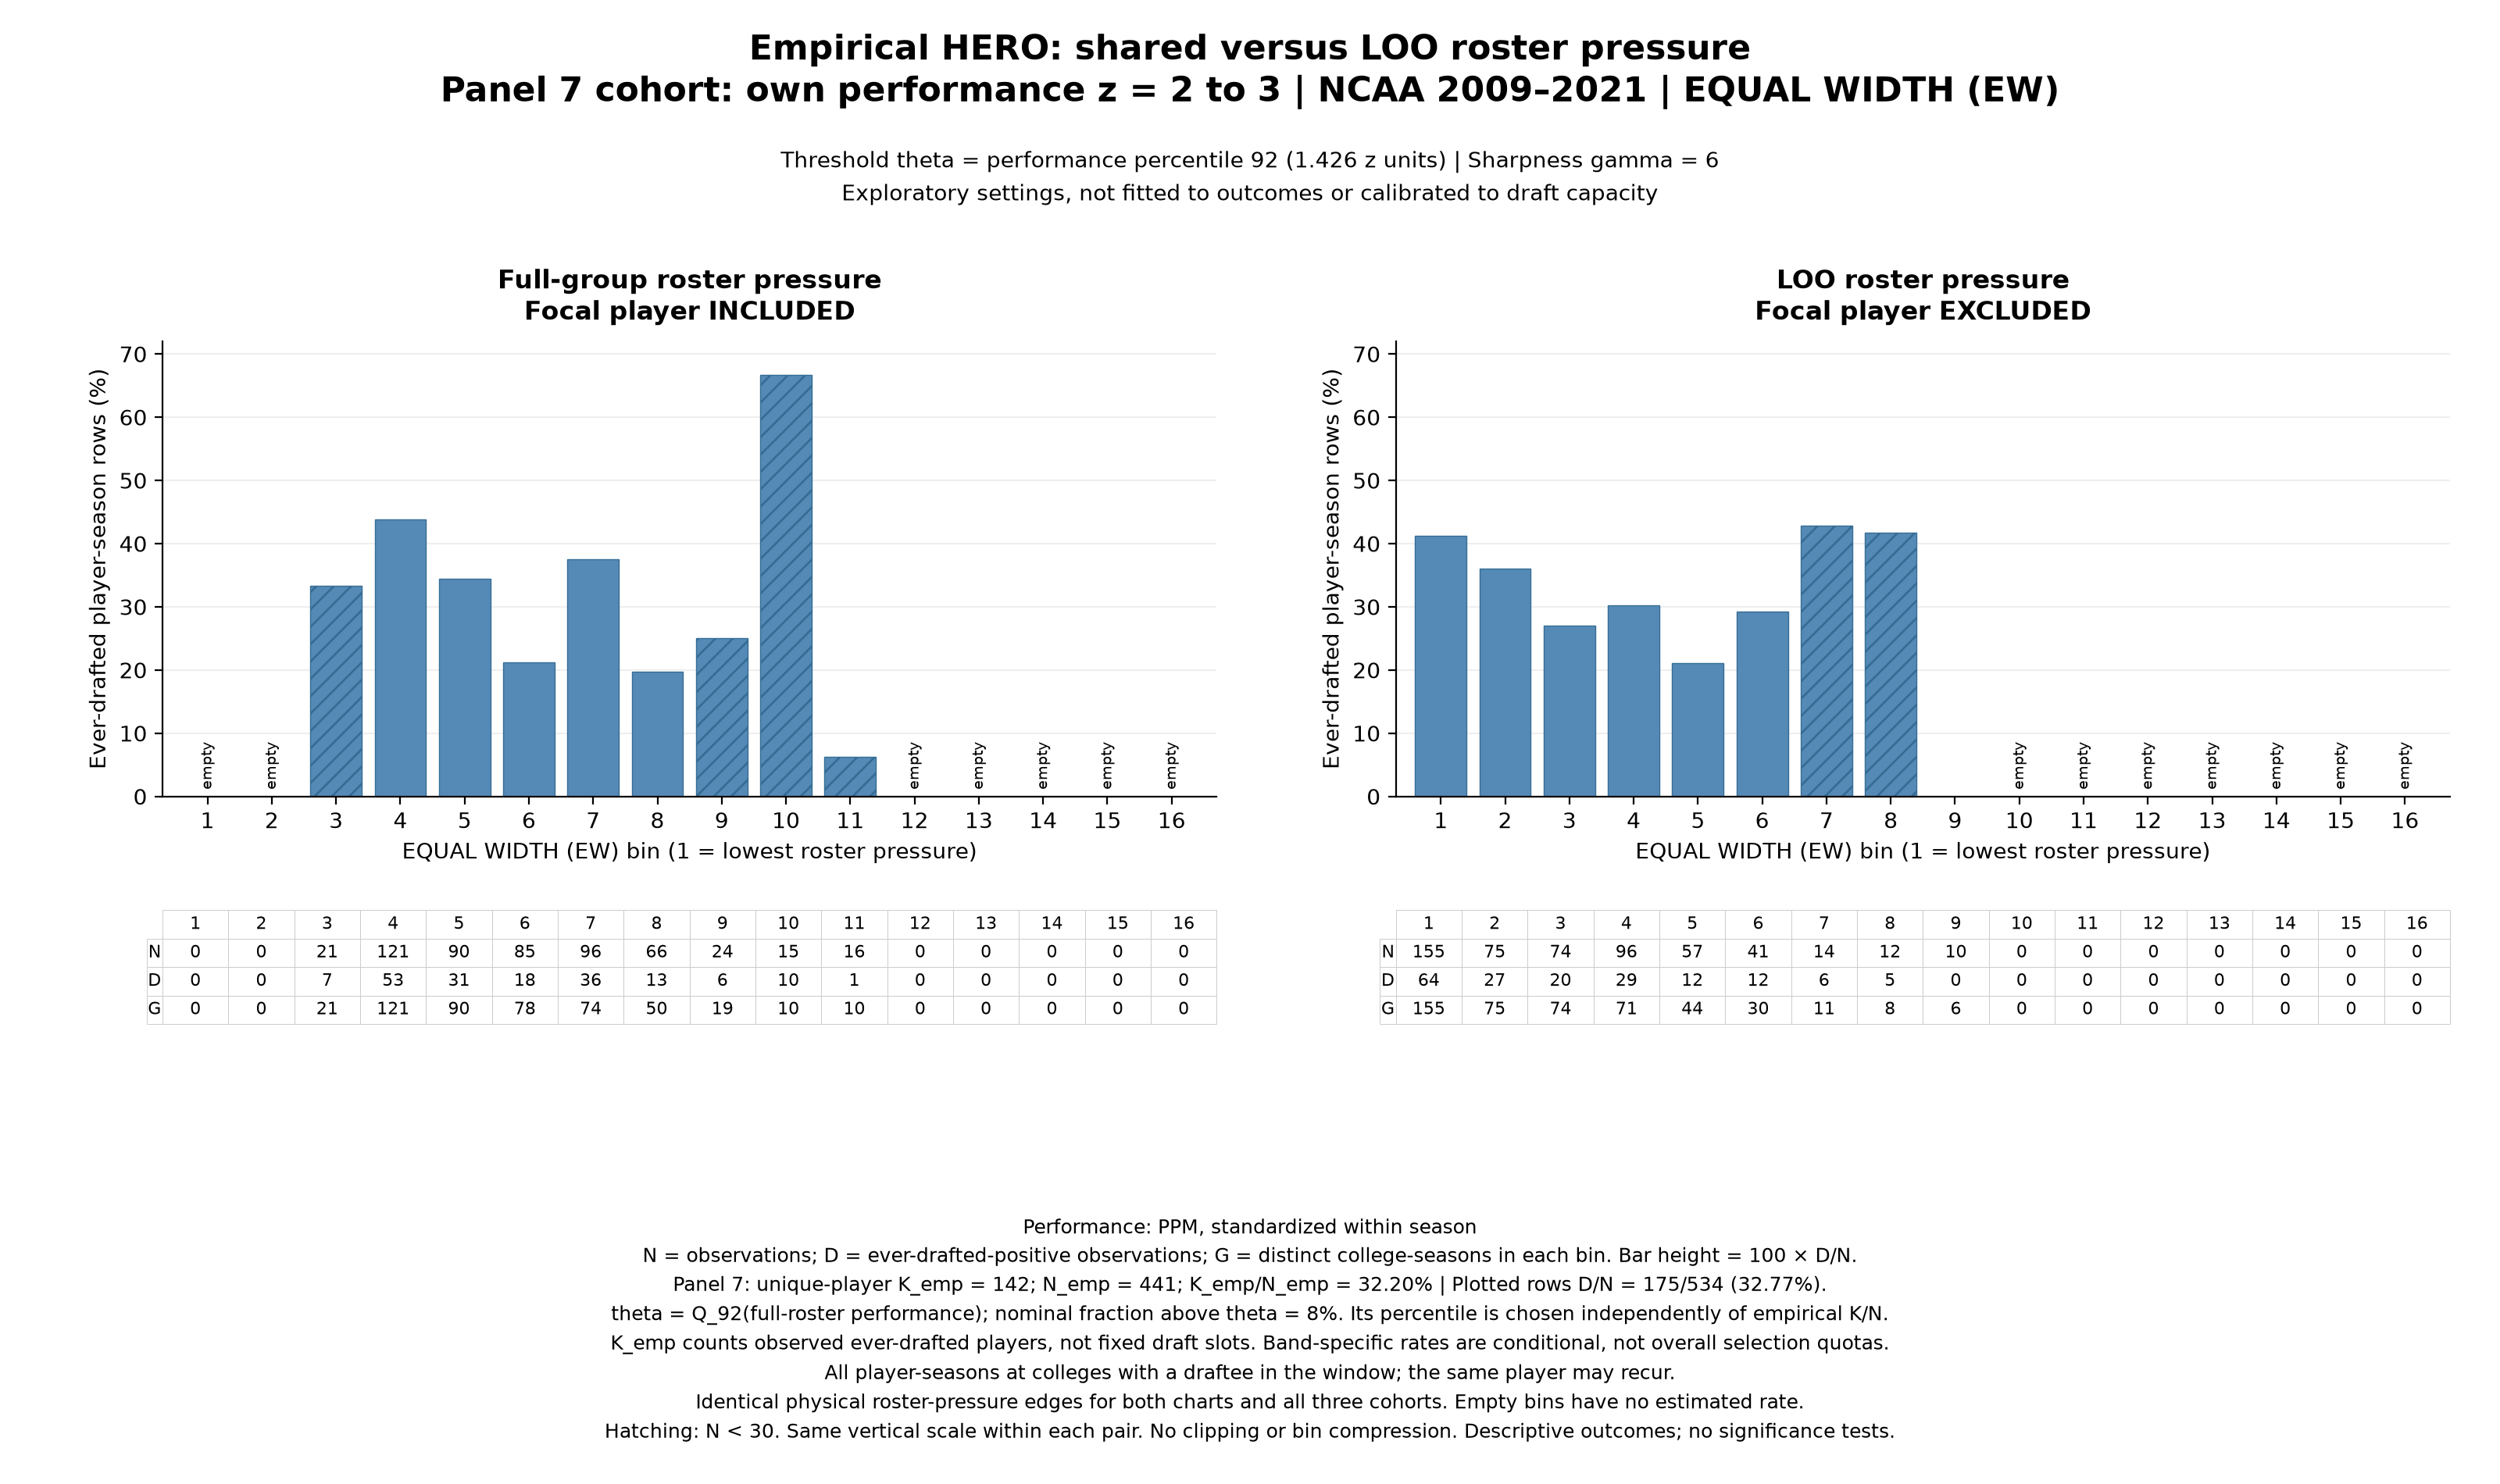

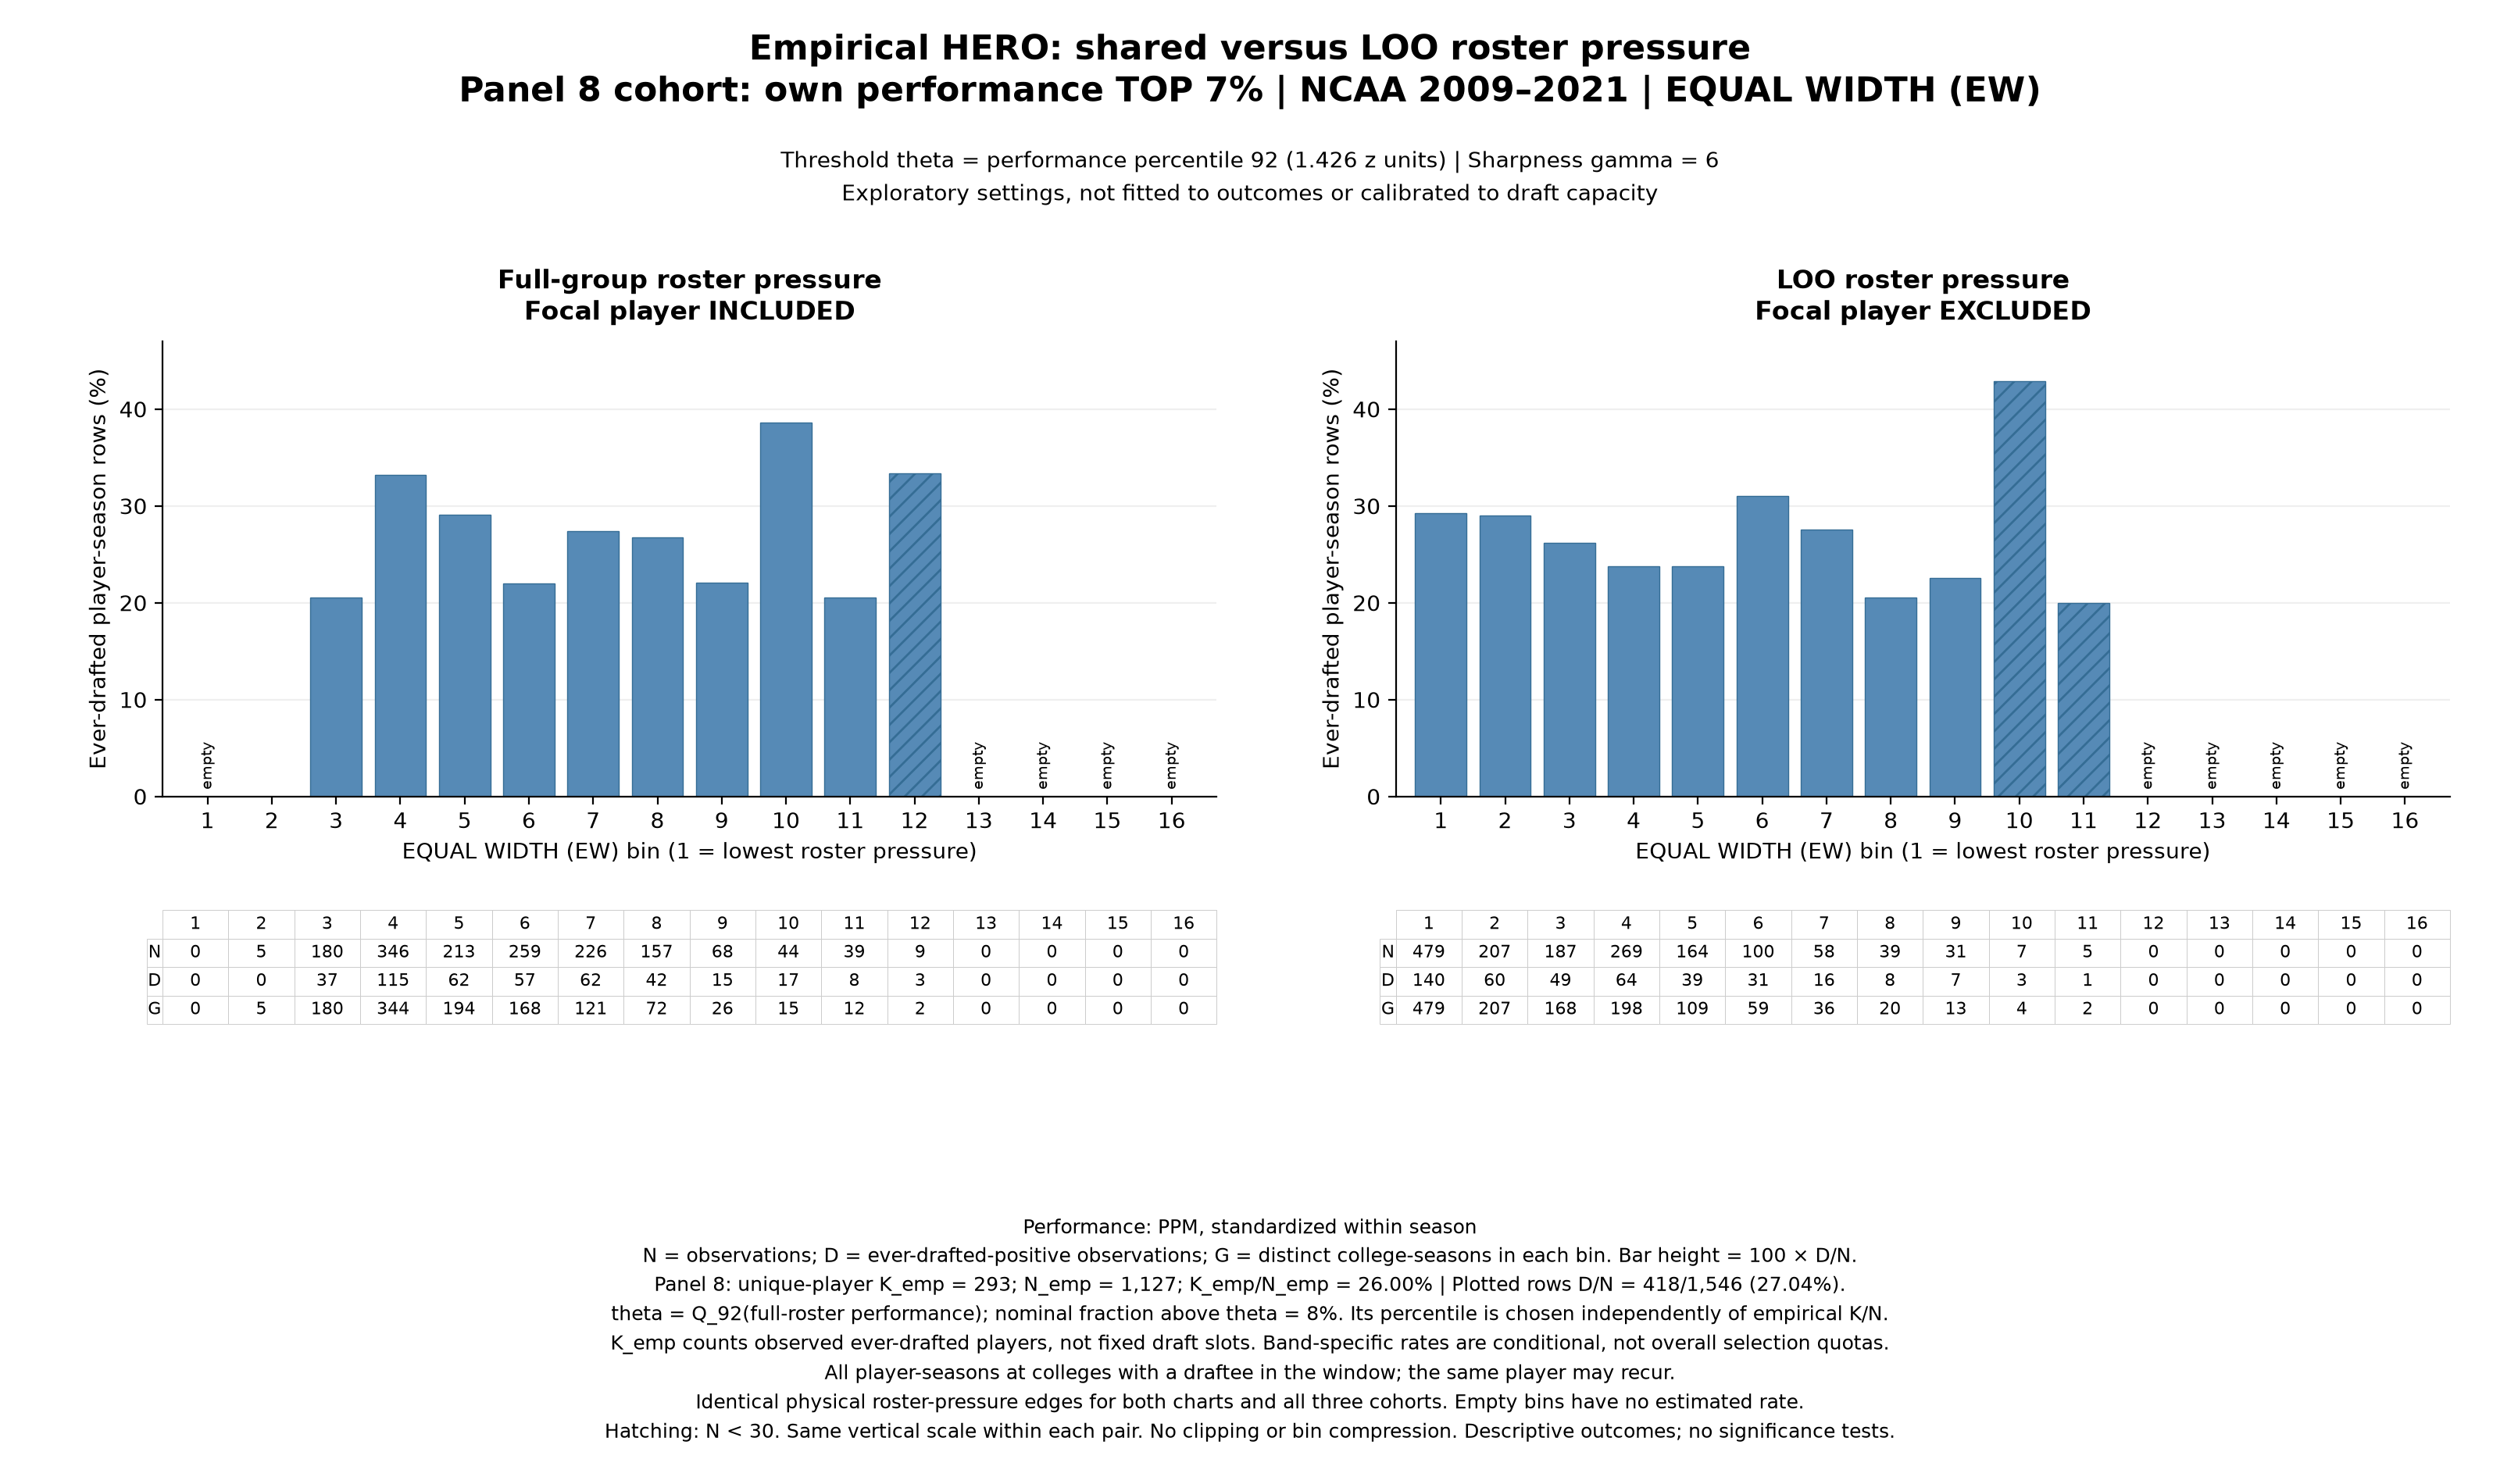

In [33]:
require_current_run()
for panel in [9, 7, 8]:
    display(Image(filename=str(RUN_FOLDER / f"HERO_panel{panel}_EW_shared_vs_LOO.png"), width=1500))

## 6. How much does excluding the focal player change the measure?

The next table follows each observation across the two versions. A negative paired change means that excluding the player lowers their measured roster pressure. “Changed quantile bin” means the observation moves when we rerank the same cohort on the other measure. It does not mean the player’s outcome changed.

The median of the paired differences is not generally equal to the difference between the two medians.

In [34]:
require_current_run()
display(summary[["panel", "median_shared", "median_loo", "median_paired_change",
                 "loo_lower_percent", "rank_correlation", "changed_quantile_bin_percent"]].round(4))


,panel,median_shared,median_loo,median_paired_change,loo_lower_percent,rank_correlation,changed_quantile_bin_percent
0,9,0.0824,0.0818,0.0049,20.0219,0.9229,68.4887
1,7,0.1425,0.0673,-0.0767,100.0000,0.9755,55.6180
2,8,0.1349,0.0666,-0.0697,100.0000,0.9562,65.2652


## 7. Check the declared alternative thresholds and sharpness values

Each sheet keeps one panel’s observations fixed. Rows vary theta’s performance percentile; columns vary gamma. Blue includes the focal player, and orange excludes them. These are quantile curves with separate memberships, matching display axes, and no clipping or coarse/fine compression. Bin counts for every curve are saved in `sensitivity_bin_counts.csv`.

The high-performance cutoff defining panel 8 remains the top 7% throughout. Changing theta changes competitive relevance, not who enters the performance band. Theta is based on the full source roster, not on the restricted high-performance band.

We show all declared combinations. These settings are not fitted, and we do not choose the combination that makes the largest downturn.

### Panel 9

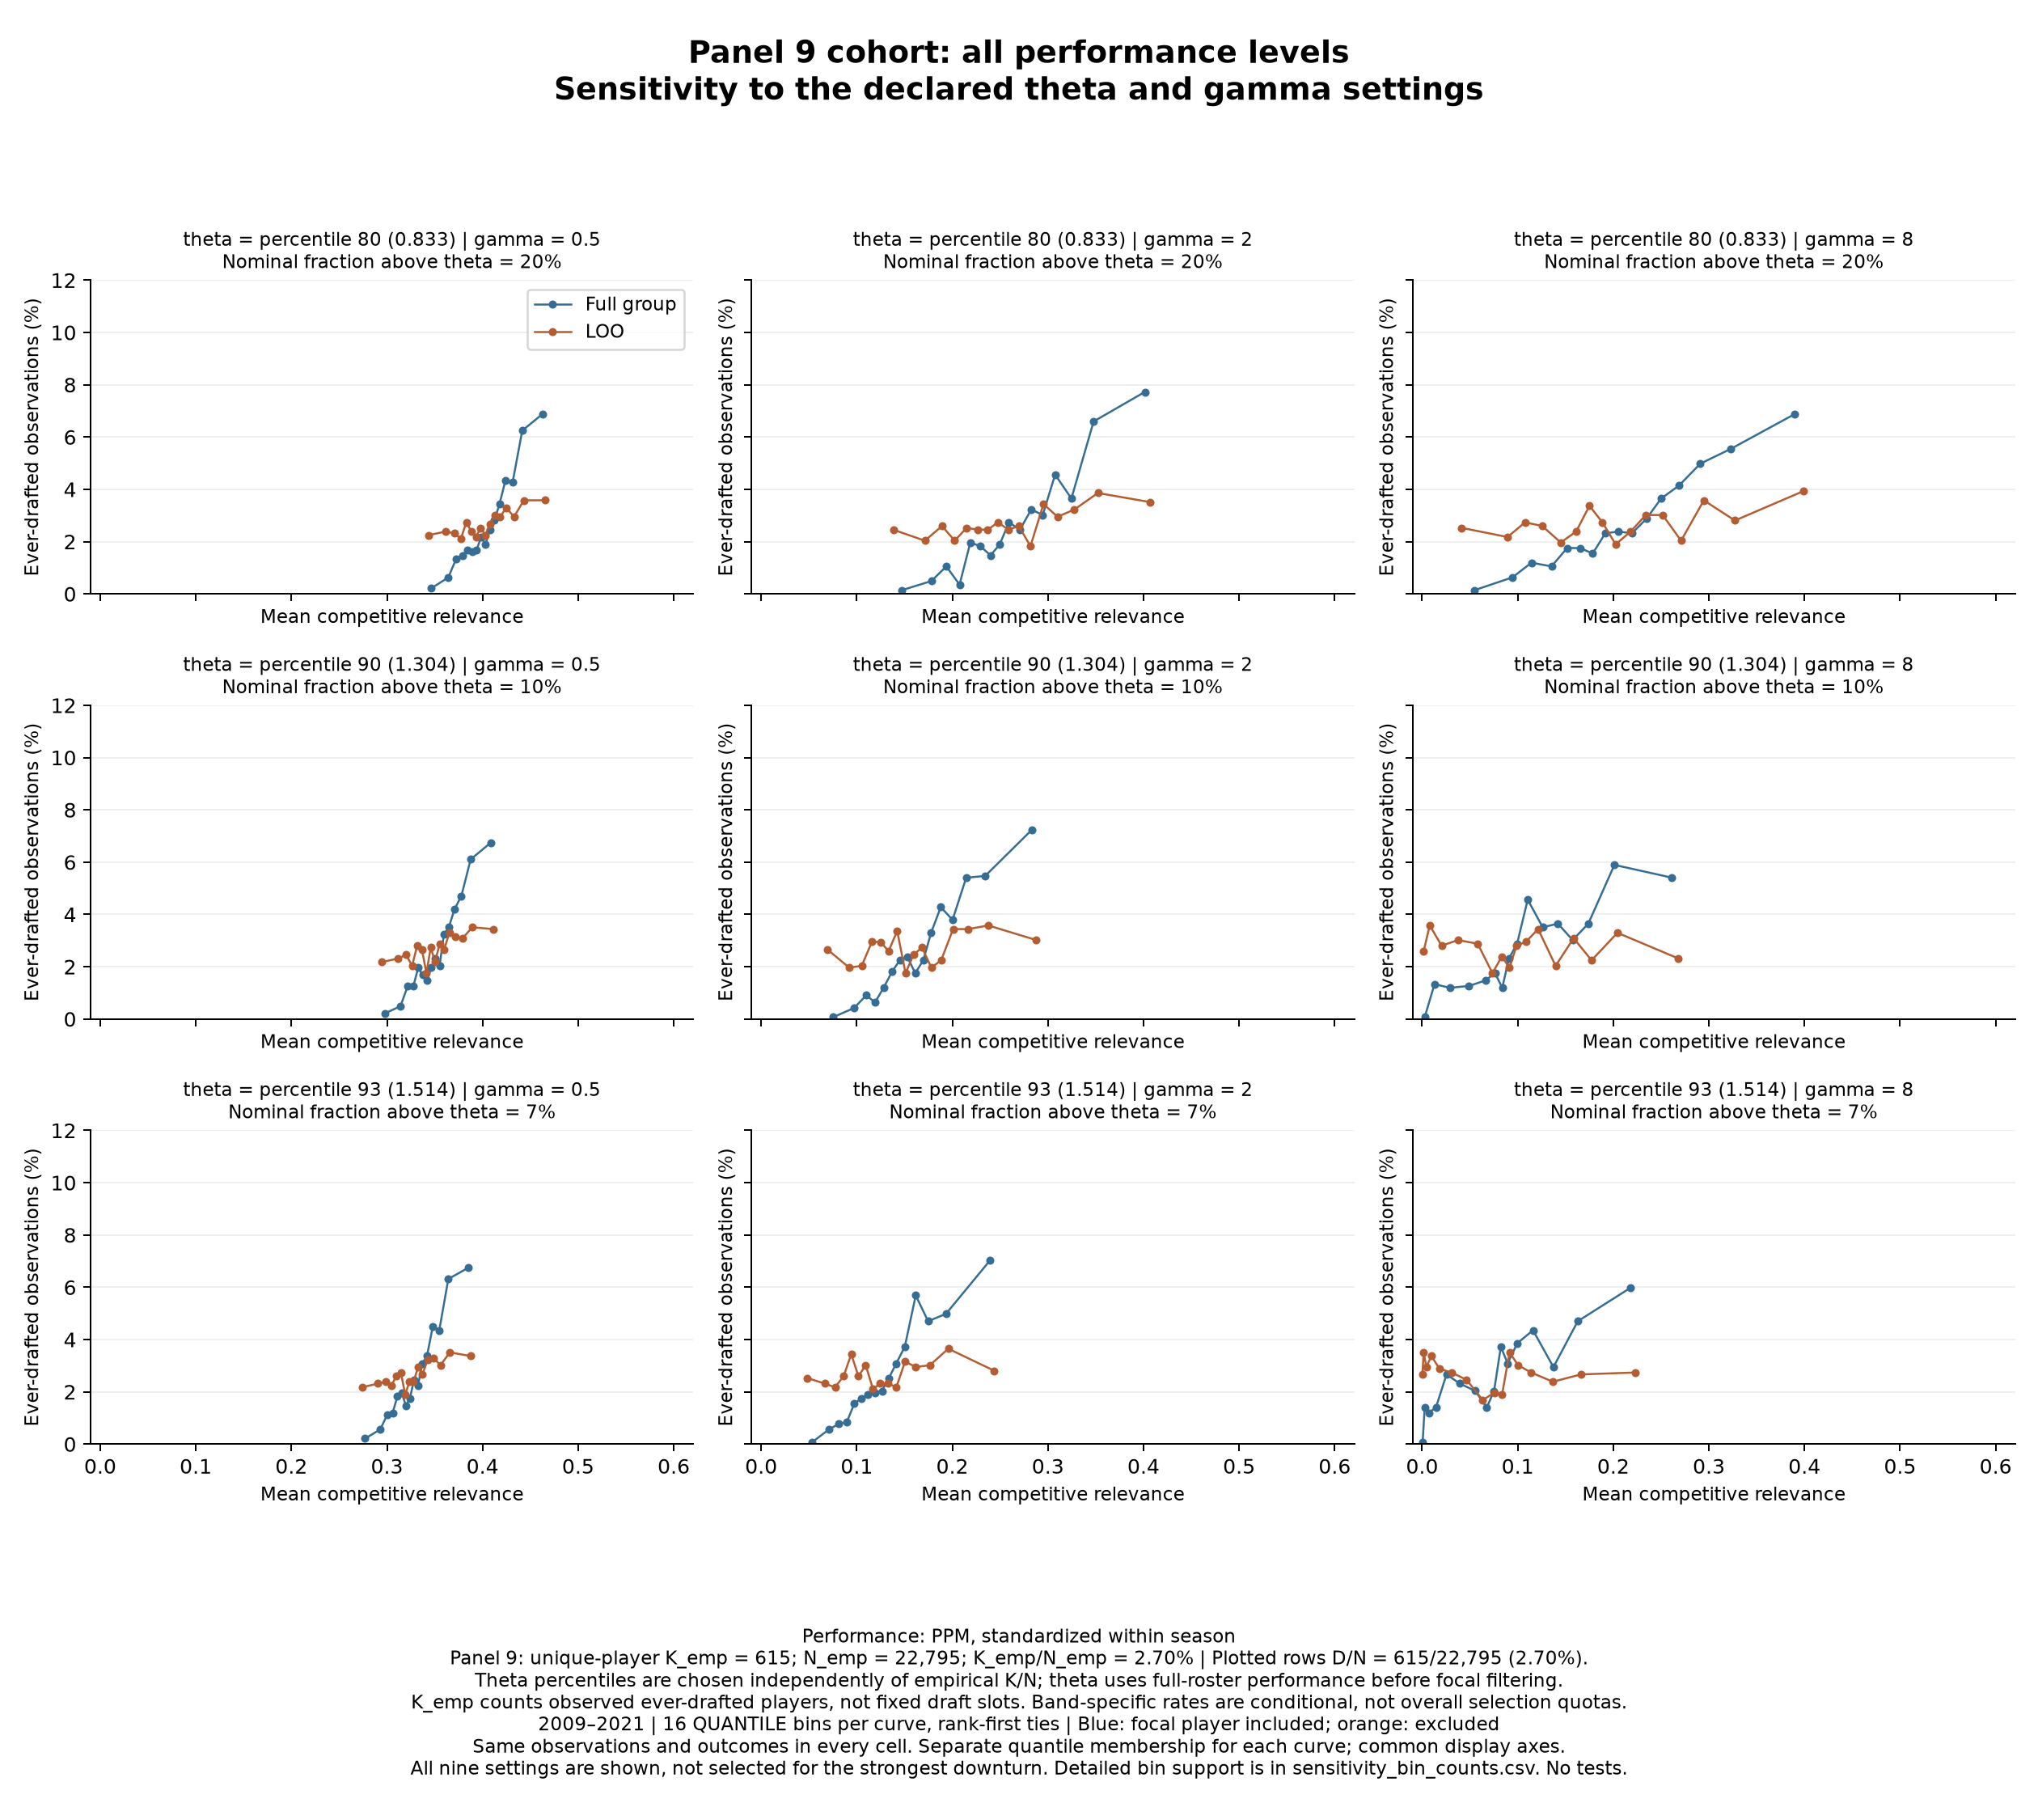

### Panel 7

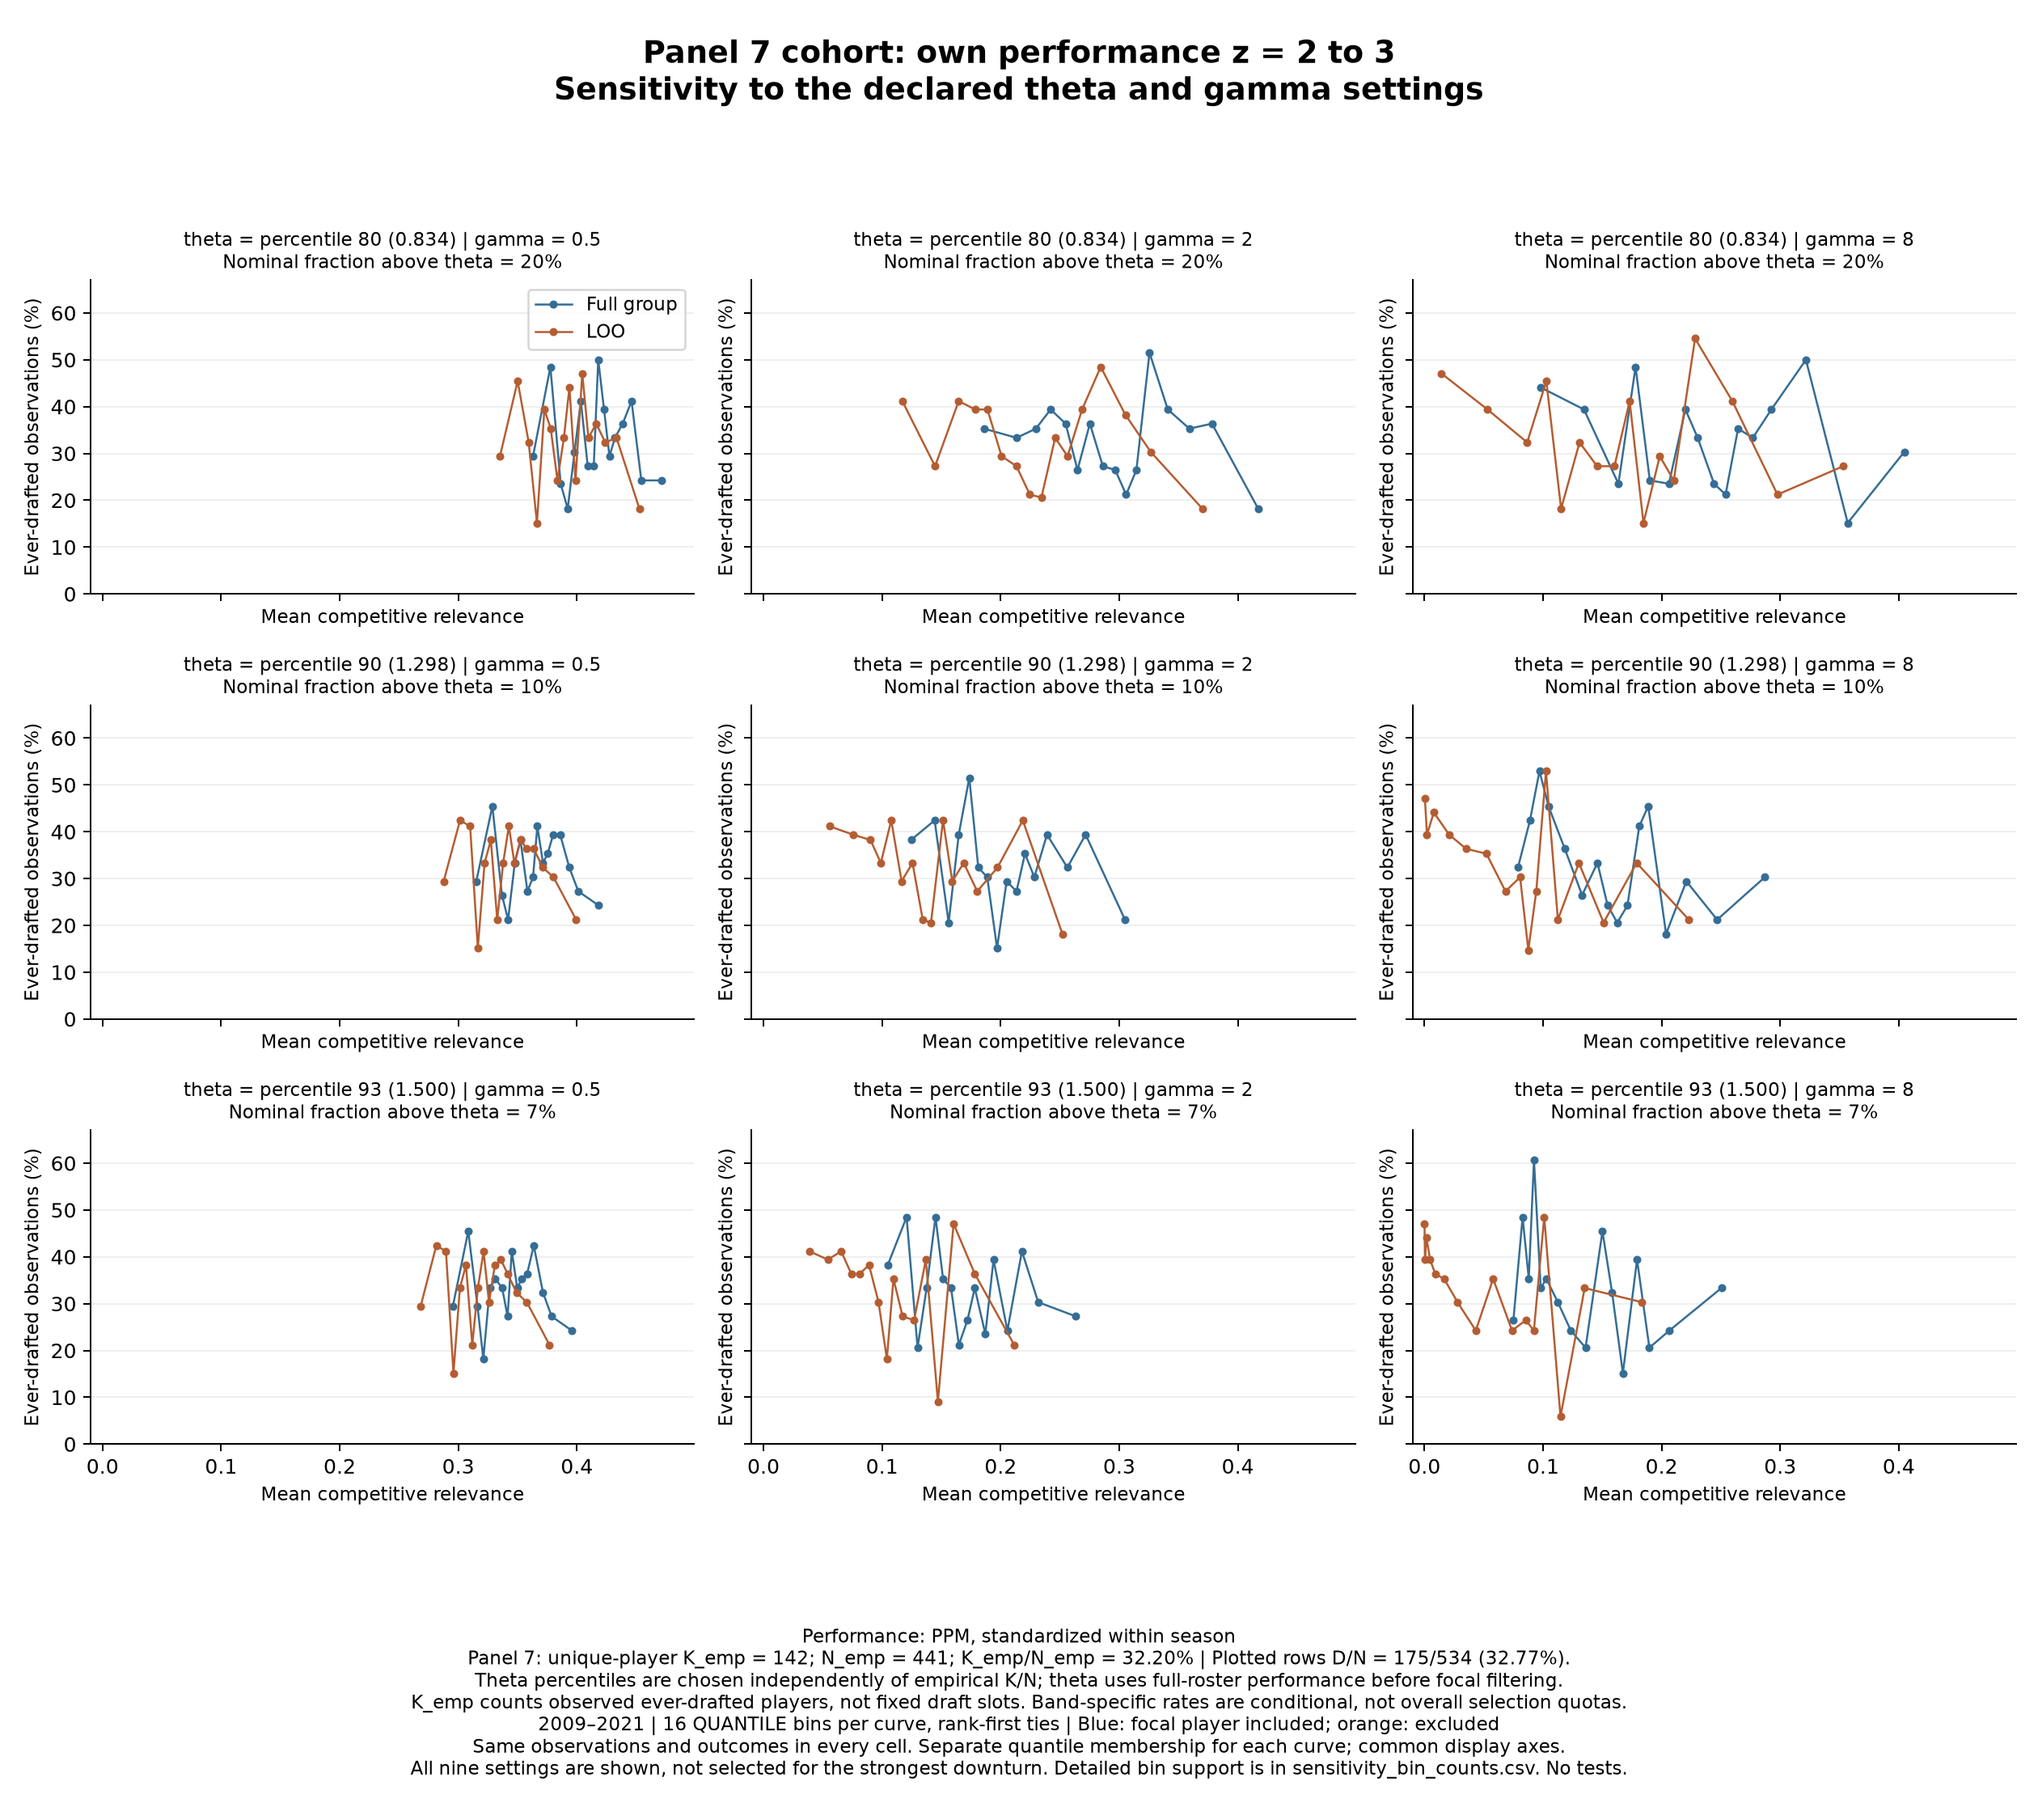

### Panel 8

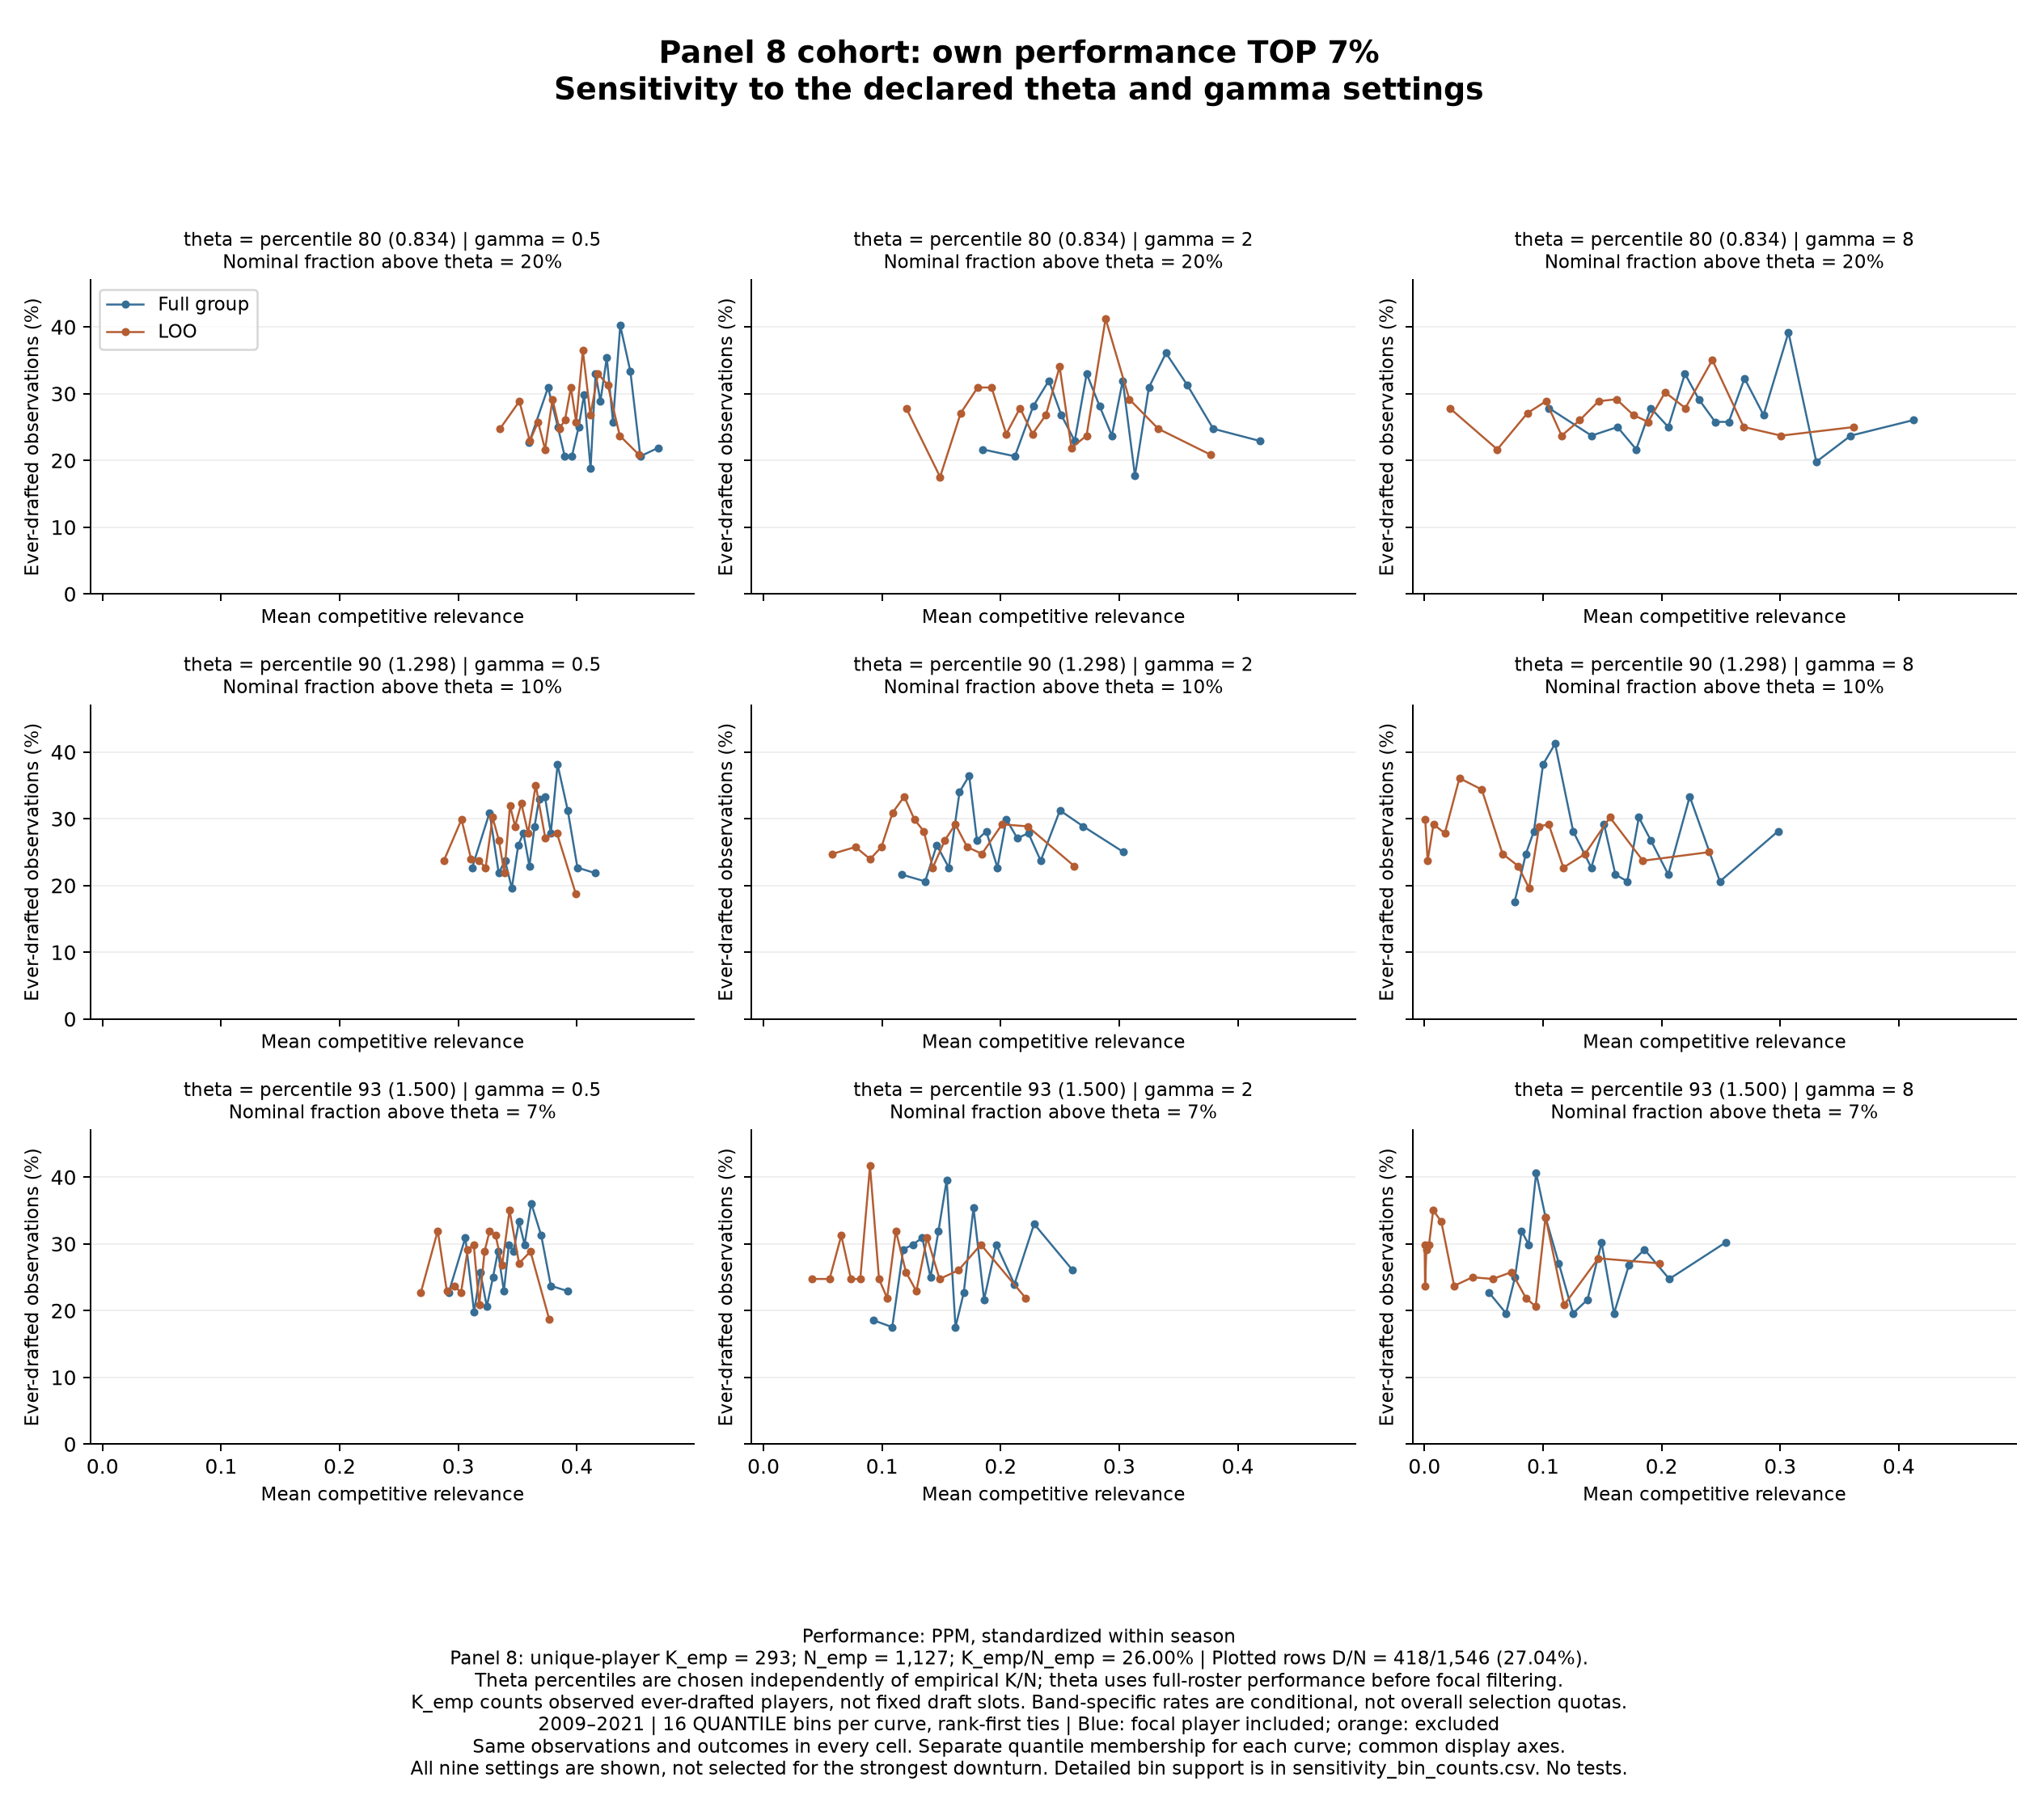

In [35]:
require_current_run()
if RUN_SENSITIVITY:
    for panel in [9, 7, 8]:
        path = RUN_FOLDER / f"panel{panel}_theta_gamma_sensitivity.png"
        if not path.exists():
            raise RuntimeError("Sensitivity figures were not generated for this run. Rebuild with RUN_SENSITIVITY = True.")
        display(Markdown(f"### Panel {panel}"))
        display(Image(filename=str(path), width=1300))
else:
    print("Sensitivity display is off. No tests were run.")


## 8. Inspect a single panel and its actual support

Choose panel 9, 7, or 8, and `quantile` or `EW`. The corresponding larger row image is available for printing or discussion. The table reports bin support for all three environmental measures, including unique drafted players and the college-seasons to which they belong.

“Drafted college-seasons” counts each distinct team/season pair represented by at least one ever-drafted player in that bin. Since the outcome is ever drafted, this is not necessarily the season in which the draft occurred.

In [36]:
PANEL_TO_INSPECT = 9
BINNING_TO_INSPECT = "quantile"  # "quantile" or "EW"
require_current_run()
if PANEL_TO_INSPECT not in [9, 7, 8] or BINNING_TO_INSPECT not in ["quantile", "EW"]:
    raise ValueError("Choose panel 9, 7, or 8 and binning quantile or EW.")
bins = pd.read_csv(RUN_FOLDER / "all_bin_counts.csv")
selected = bins.loc[(bins.panel == PANEL_TO_INSPECT) & (bins.method == BINNING_TO_INSPECT)]
print("Larger row image:", RUN_FOLDER / f"panel{PANEL_TO_INSPECT}_{BINNING_TO_INSPECT}_comparison.png")
display(selected[["axis", "bin", "n", "positive_rows", "rate", "distinct_players",
                  "distinct_drafted_players", "colleges", "team_seasons", "drafted_colleges", "drafted_team_seasons"]])


Larger row image: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison/runs/20261023_113742_690479/panel9_quantile_comparison.png


,axis,bin,n,positive_rows,rate,distinct_players,distinct_drafted_players,colleges,team_seasons,drafted_colleges,drafted_team_seasons
0,loo_performance,1,1425,28,0.019649,1425,28,230,501,24,27
1,loo_performance,2,1425,37,0.025965,1425,37,299,788,29,34
2,loo_performance,3,1425,33,0.023158,1425,33,305,874,30,32
3,loo_performance,4,1424,28,0.019663,1424,28,311,934,22,25
4,loo_performance,5,1425,47,0.032982,1425,47,330,1005,36,45
5,loo_performance,6,1425,32,0.022456,1425,32,336,1030,23,29
6,loo_performance,7,1424,27,0.018961,1424,27,338,1059,20,25
7,loo_performance,8,1425,38,0.026667,1425,38,342,1051,28,37
8,loo_performance,9,1425,39,0.027368,1425,39,340,1059,32,38
9,loo_performance,10,1424,28,0.019663,1424,28,336,1036,21,28


## 9. How to read the first result

Begin with panel 9 at the starting settings. Does the rising full-group curve remain when the focal player is excluded? Full-group roster pressure contains the focal player’s own competitive relevance. Because own performance is associated with drafting, part of a relationship on that axis can reflect self-inclusion rather than a peer effect. The LOO comparison helps reveal how much the visual pattern depends on that inclusion; it does not by itself identify causality.

Next examine panel 7, followed by panel 8. Those restrict own performance, but do not make it identical across observations. Their ever-drafted labels also repeat across eligible player-seasons. Look at the count rows before interpreting the right tail, and compare quantile with EW before deciding that a visible downturn persists.

The notebook intentionally stops at descriptive comparisons. No selection penalty is applied, no outcome is changed, and neither congestion nor a causal peer effect is estimated. The previous tests and manuscript remain untouched. The separate question about tie-preserving quantiles is still parked.

**Files to keep:** this notebook, its companion `roster_pressure_analysis.py`, and the `runs` folder. Every run has its own figures, printable PDF, full counts, membership records, settings, and source fingerprints. `latest_run.json` points to the newest completed run.